# Taller 1 — Notebook 03: Desarrollo de la estrategia

**MINE-4101 · Ciencia de Datos Aplicada**

Cubre el **punto 3 (40 %)** del taller: implementa la estrategia definida en el notebook 02,
contrasta ocho hipótesis explícitas con su tamaño de efecto, separa lo que
aporta cada atributo de lo que se debe al valor y la modalidad, cierra con una matriz exploratoria de cada
característica frente a cada comportamiento y reporta **tanto los resultados significativos
como los que no lo son**.

**Herramientas.** Las pruebas primarias son las cinco del árbol de decisión del curso: Z test,
T test, ANOVA, chi-cuadrado y correlación. Los intervalos de confianza y la estadística
descriptiva completan el análisis. No se usan modelos predictivos.

**Requisito:** ejecutar antes [`01_entendimiento_datos.ipynb`](01_entendimiento_datos.ipynb).

**Las ocho preguntas, en palabras simples:**

| # | La pregunta | Herramienta |
|---|---|---|
| H1 | ¿Alargar el plazo depende de cómo se contrató (licitación, mínima cuantía, directa…)? | Chi-cuadrado |
| H2 | Si se ordenan los contratos del más barato al más caro, ¿la desviación sube con el precio? | Correlación |
| H2b | ¿Los contratos que se desvían valen más que los que no? | Z test |
| H3 | ¿Pagar solo una parte pasa más en gasto de inversión o en gasto de funcionamiento? | Chi-cuadrado |
| H4 | ¿Alargar el plazo depende de si la entidad es nacional o territorial? ¿Y del sector? | Chi-cuadrado (dos veces) |
| H5 | ¿Se alargan más los contratos que dicen «prorrogable»? ¿Y los que permiten pago adelantado? | Chi-cuadrado (dos veces) |
| H6 | Entre los contratos que sí se alargaron, ¿el número de días añadidos cambia según el sector? | ANOVA |
| H7 | Control: ¿el género del representante legal tiene que ver con la desviación? | Chi-cuadrado |
| H8 | ¿Dejar de registrar pagos se concentra en ciertos tipos de entidad o sectores? | Chi-cuadrado (dos veces) |

Son ocho hipótesis pero doce pruebas, porque H4, H5 y H8 hacen dos preguntas cada una y H2 tiene
dos versiones. H7 y la parte del pago adelantado de H5 se hacen esperando un «no», como el
placebo de un experimento médico: si el género saliera importante, querría decir que el método
detecta cosas que no existen.

**Cómo leer los resultados.** Cada sección plantea su hipótesis como un par: H₀ dice que no hay
relación y H₁ que sí. El valor p responde a esta pregunta: si en realidad no hubiera ninguna relación, ¿qué tan raro
sería ver, solo por casualidad, una diferencia como la observada o mayor? Si es menor que 0,05
(menos de 1 en 20), el resultado es estadísticamente significativo: es difícil explicarlo como
casualidad, y la sección dice «se rechaza H₀».

> **Advertencia metodológica que atraviesa todo el notebook.** Con n ≈ 196.000, el valor p es
> casi inútil como criterio de decisión: prácticamente cualquier diferencia alcanza
> significancia. Significativo no quiere decir importante: cada contraste reporta por tanto su
> **tamaño de efecto**, es decir, cuánto cambia de verdad la tasa de un grupo a otro, y la
> sección 10 muestra gráficamente que significancia y relevancia son cosas distintas.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config
from src.carga import cargar_limpio
from src.inferencia import (agrupar_raras, delta_cliff,
                            ficha_prueba, interpretar_v, prueba_anova,
                            prueba_chi2, prueba_correlacion, prueba_kruskal,
                            prueba_proporciones, prueba_tendencia, prueba_z_medias,
                            v_cramer)
from src.viz import AZUL, AZUL_CLARO, GRIS, NARANJA, ROJO, VERDE, aplicar_estilo, guardar

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
config.asegurar_directorios()
pd.set_option("display.width", 190)
np.random.seed(config.SEMILLA)

df = cargar_limpio()
M_TOTAL = df
M_PAGO = df[(df["pct_ejecucion_financiera"] > 0) & df["desenlace_observable"]]

print(f"M_TOTAL = {len(M_TOTAL):,}   M_PAGO = {len(M_PAGO):,}")
print(f"tasa base de desviacion: {100*df['desviacion'].mean():.2f} %")

# --- Paso 2 del procedimiento: los criterios de decision, antes de ver nada ---
print("\nCriterios fijados a priori en src/config.py:")
print(f"  nivel de significancia       alfa = {config.ALFA}")
print(f"  relevancia practica          V de Cramer  >= {config.V_MINIMA_UTIL}")
print(f"                               diferencia   >= {config.DIF_MINIMA_PP} pp")
print(f"                               correlacion  >= {config.RHO_MINIMO_UTIL}")
print(f"                               eta cuadrado >= {config.ETA2_MINIMO_UTIL}")
print(f"                               factor valor >= {config.FACTOR_MINIMO_UTIL}x")

RES = []   # pruebas primarias: solo las del arbol de decision del curso
ROB = []   # robustez no parametrica; se reporta aparte de las pruebas primarias

  dataset limpio: 196,391 filas x 70 columnas


M_TOTAL = 196,391   M_PAGO = 88,363
tasa base de desviacion: 13.55 %

Criterios fijados a priori en src/config.py:
  nivel de significancia       alfa = 0.05
  relevancia practica          V de Cramer  >= 0.1
                               diferencia   >= 2.0 pp
                               correlacion  >= 0.3
                               eta cuadrado >= 0.06
                               factor valor >= 1.5x


---
## H1 - La tasa de adición de plazo difiere entre modalidades de contratación

**En palabras simples:** ¿alargar el plazo depende de cómo se contrató (licitación, mínima cuantía, directa…)?

**H₀:** la adición de plazo es independiente de la modalidad.
**H₁:** existe asociación.

*Rama del árbol de decisión:* categórica vs. categórica → **chi-cuadrado**.

In [2]:
r1 = prueba_chi2(M_TOTAL, "modalidad_de_contratacion", "tiene_adicion", "H1")
RES.append(r1)
display(ficha_prueba(
    r1,
    "la adicion de plazo es independiente de la modalidad de contratacion",
    "la tasa de adicion difiere entre modalidades",
    alpha=config.ALFA, umbral=config.V_MINIMA_UTIL))

tasas = (M_TOTAL.groupby("modalidad_de_contratacion", observed=True)["tiene_adicion"]
         .agg(n="size", tasa="mean").query("n >= 500").sort_values("tasa"))
tasas["tasa_%"] = (100 * tasas["tasa"]).round(2)
display(tasas[["n", "tasa_%"]].sort_values("tasa_%", ascending=False))

,Detalle
Paso,
1. Hipotesis nula (H0),la adicion de plazo es independiente de la mod...
1. Hipotesis alternativa (H1),la tasa de adicion difiere entre modalidades
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,"4,095.6156 (gl = 8)"
4. Valor p,< 1e-300
4. Tamano de efecto,V de Cramer = 0.1444 (pequeno)


,n,tasa_%
modalidad_de_contratacion,,
Licitación pública,2330,25.84
Contratación régimen especial (con ofertas),6154,18.36
Selección abreviada subasta inversa,32907,15.77
Selección abreviada de menor cuantía,8822,14.74
Contratación directa (con ofertas),5001,8.96
Contratación directa,3938,7.54
Mínima cuantía,117753,7.18
Contratación régimen especial,19250,6.23


figura: reports/figures/h1_adicion_por_modalidad.png


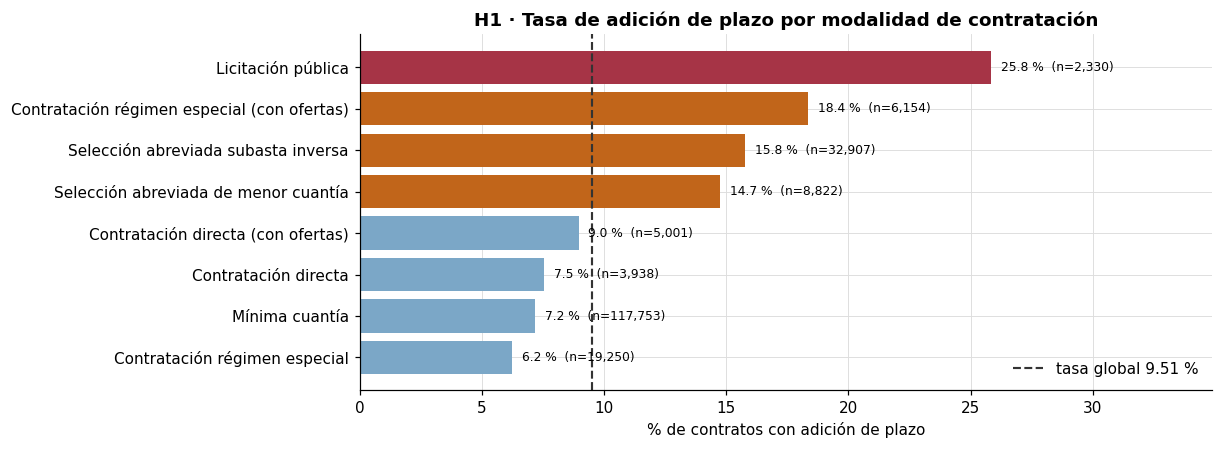

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.2))
base = 100 * M_TOTAL["tiene_adicion"].mean()
colores = [ROJO if t > 2 * base else (NARANJA if t > base else AZUL_CLARO)
           for t in tasas["tasa_%"]]
ax.barh(tasas.index.astype(str), tasas["tasa_%"], color=colores)
ax.axvline(base, color="#333", ls="--", lw=1.4, label=f"tasa global {base:.2f} %")
ax.set_xlabel("% de contratos con adición de plazo")
ax.set_title("H1 · Tasa de adición de plazo por modalidad de contratación")
ax.legend()
for i, (v, n) in enumerate(zip(tasas["tasa_%"], tasas["n"])):
    ax.text(v + 0.4, i, f"{v:.1f} %  (n={n:,})", va="center", fontsize=8)
ax.set_xlim(0, tasas["tasa_%"].max() * 1.35)
print("figura:", guardar(fig, "h1_adicion_por_modalidad"))
plt.show()

**Resultado.** Se rechaza H₀. La V de Cramér de **0,144** es el efecto más grande entre los
contrastes de adición del plan, y el único de ellos que alcanza la categoría «pequeño» de Cohen
en lugar de «despreciable». La matriz de la sección 13 muestra que el valor, que H2 mide en otra
escala, pesa todavía más sobre la adición (V = 0,190). La licitación pública adiciona plazo en el **25,8 %** de los casos
frente al **6,2 %** de la contratación de régimen especial: un factor de **4,1**.

**Lectura de negocio.** La modalidad es un dato conocido en el momento de la firma y clasifica
el contrato sin ambigüedad, lo que la convierte en el primer criterio de focalización.

---
## H2 - Los contratos de mayor valor se desvían más

Dos preguntas distintas que conviene no mezclar, y que se contrastan por separado.

**H2 - Si se ordenan los contratos del más barato al más caro, ¿la desviación sube con el precio?**
**H₀:** la tasa de desviación no guarda relación con el nivel de valor del contrato.
**H₁:** crece con el valor.
*Rama del árbol:* numérica vs. numérica → **Correlation Test**. Se correlaciona el índice de
decil (1-10) contra la tasa de desviación observada en ese decil, que son las dos variables
numéricas que la hipótesis relaciona de verdad.

**H2b - ¿Los contratos que se desvían valen más que los que no?**
**H₀:** la media de `log10(valor)` es igual en contratos con y sin desviación.
**H₁:** difiere.
*Rama del árbol:* numérica vs. categórica de dos grupos con muestras grandes → **Z Test**, en
su variante de varianzas desiguales, que es la misma elección conservadora que hace el ejemplo
del curso al preferir Welch. Se trabaja sobre `log10` y no sobre pesos porque el notebook 01
mostró que un solo contrato concentra el 99,47 % de la suma; la diferencia de medias en
logaritmo se lee después como un **factor multiplicativo**, que es la forma interpretable.

In [4]:
d2 = M_TOTAL.dropna(subset=["valor_del_contrato"]).copy()
d2["decil_valor"] = pd.qcut(d2["valor_del_contrato"], 10, labels=False, duplicates="drop")

g2 = (d2.groupby("decil_valor")
      .agg(n=("desviacion", "size"), tasa=("desviacion", "mean"),
           mediana_valor=("valor_del_contrato", "median"))
      .reset_index())
g2["decil"] = g2["decil_valor"] + 1
g2["tasa_%"] = (100 * g2["tasa"]).round(2)
display(g2[["decil", "n", "mediana_valor", "tasa_%"]])

# --- H2: Correlation Test entre nivel de valor y tasa de desviacion ---
r2 = prueba_correlacion(g2, "decil", "tasa_%", "pearson", "H2")
RES.append(r2)
display(ficha_prueba(
    r2,
    "la tasa de desviacion no guarda relacion con el nivel de valor",
    "la tasa de desviacion crece con el valor del contrato",
    alpha=config.ALFA, umbral=config.RHO_MINIMO_UTIL))

# --- H2b: Z test de dos medias sobre log10(valor) ---
r2b = prueba_z_medias(M_TOTAL, "log_valor", "desviacion", True, False, "H2b",
                      escala_log10=True, alpha=config.ALFA)
RES.append(r2b)
display(ficha_prueba(
    r2b,
    "la media de log10(valor) es igual en contratos con y sin desviacion",
    "los contratos con desviacion tienen un valor medio mayor",
    alpha=config.ALFA, umbral=np.log10(config.FACTOR_MINIMO_UTIL)))
print(f"mediana del valor  CON desviacion = "
      f"{d2.loc[d2['desviacion'], 'valor_del_contrato'].median():>15,.0f} COP")
print(f"mediana del valor  SIN desviacion = "
      f"{d2.loc[~d2['desviacion'], 'valor_del_contrato'].median():>15,.0f} COP")

# --- Robustez no parametrica, aparte de las pruebas primarias ---
from scipy import stats as st

rho_dec = prueba_correlacion(g2, "decil", "tasa_%", "spearman", "H2-rob")
rho_fila = prueba_tendencia(d2, "decil_valor", "desviacion", "H2-rob-fila")
a = d2.loc[d2["desviacion"], "log_valor"]
b = d2.loc[~d2["desviacion"], "log_valor"]
p_mw = float(st.mannwhitneyu(a, b, alternative="two-sided").pvalue)
delta = delta_cliff(a, b)
ROB += [rho_dec, rho_fila,
        {"hipotesis": "H2b-rob", "variable": "log_valor", "objetivo": "desviacion",
         "prueba": "Mann-Whitney U", "n": len(d2), "p": p_mw,
         "efecto": "delta de Cliff", "valor_efecto": delta}]

print("\nVerificacion de robustez")
print(f"  Spearman entre deciles   rho = {rho_dec['valor_efecto']:+.4f}   "
      f"(monotonia perfecta: sube en los 10 deciles sin una sola excepcion)")
print(f"  Spearman fila a fila     rho = {rho_fila['valor_efecto']:+.4f}   "
      f"p = {rho_fila['p']:.3e}")
print(f"  Mann-Whitney             p = {p_mw:.3e}   delta de Cliff = {delta:+.4f}")
print("  -> la alternativa no parametrica coincide con el Z test")

,decil,n,mediana_valor,tasa_%
0,1,19643,2.310000e+06,4.17
1,2,19636,6.626070e+06,7.23
2,3,19639,1.202200e+07,9.15
3,4,19639,1.969250e+07,10.06
4,5,19647,2.836568e+07,11.19
5,6,19631,3.967437e+07,13.58
6,7,19639,6.000000e+07,14.98
7,8,19639,1.000000e+08,16.68
8,9,19639,2.181343e+08,20.20
9,10,19639,8.000000e+08,28.22


,Detalle
Paso,
1. Hipotesis nula (H0),la tasa de desviacion no guarda relacion con e...
1. Hipotesis alternativa (H1),la tasa de desviacion crece con el valor del c...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,Correlacion de Pearson
3. Supuesto a validar,ambas variables numericas; Spearman no exige r...
3. Verificacion del supuesto,cumple
4. Estadistico,0.9541
4. Valor p,1.834e-05
4. Tamano de efecto,"r de Pearson = 0.9541 IC 95 % [0.8127, 0.9894]"


,Detalle
Paso,
1. Hipotesis nula (H0),la media de log10(valor) es igual en contratos...
1. Hipotesis alternativa (H1),los contratos con desviacion tienen un valor m...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,Z test de dos medias
3. Supuesto a validar,n >= 30 por grupo (TCL)
3. Verificacion del supuesto,cumple
4. Estadistico,83.9714
4. Error estandar,0.00534
4. Valor p,< 1e-300


mediana del valor  CON desviacion =      71,079,856 COP
mediana del valor  SIN desviacion =      30,000,000 COP

Verificacion de robustez
  Spearman entre deciles   rho = +1.0000   (monotonia perfecta: sube en los 10 deciles sin una sola excepcion)
  Spearman fila a fila     rho = +0.1842   p = 0.000e+00
  Mann-Whitney             p = 0.000e+00   delta de Cliff = +0.3156
  -> la alternativa no parametrica coincide con el Z test


figura: reports/figures/h2_desviacion_por_decil_valor.png


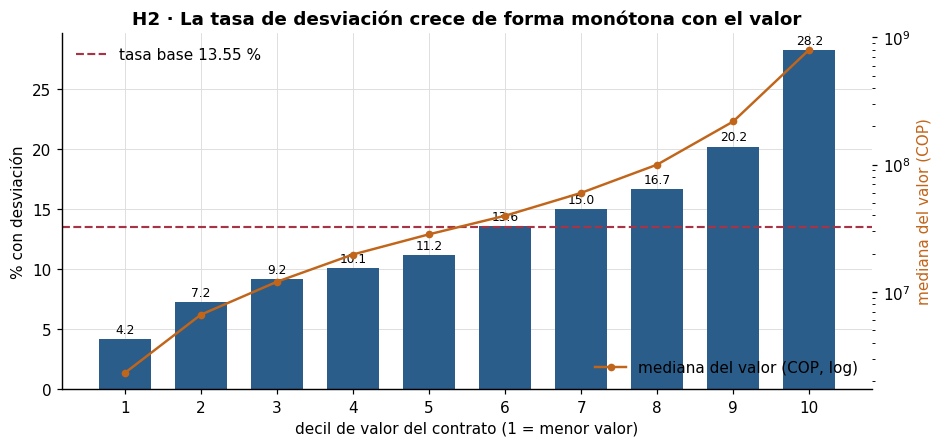

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = g2["decil"]
ax.bar(x, g2["tasa_%"], color=AZUL, width=0.68)
ax.axhline(100 * M_TOTAL["desviacion"].mean(), color=ROJO, ls="--", lw=1.4,
           label=f"tasa base {100*M_TOTAL['desviacion'].mean():.2f} %")
ax.set_xticks(x)
ax.set_xlabel("decil de valor del contrato (1 = menor valor)")
ax.set_ylabel("% con desviación")
ax.set_title("H2 · La tasa de desviación crece de forma monótona con el valor")
for xi, yi, mv in zip(x, g2["tasa_%"], g2["mediana_valor"]):
    ax.text(xi, yi + 0.5, f"{yi:.1f}", ha="center", fontsize=8)
ax2 = ax.twinx()
ax2.plot(x, g2["mediana_valor"], color=NARANJA, marker="o", ms=4, lw=1.6,
         label="mediana del valor (COP, log)")
ax2.set_yscale("log")
ax2.set_ylabel("mediana del valor (COP)", color=NARANJA)
ax2.grid(False)
ax.legend(loc="upper left")
ax2.legend(loc="lower right")
print("figura:", guardar(fig, "h2_desviacion_por_decil_valor"))
plt.show()

**Resultado.** Se rechaza H₀ por las dos vías. La progresión es **monótona sin excepción**: del
**4,2 %** en el decil más bajo al **28,2 %** en el más alto, un factor de **6,8**, con
r = **0,954** (IC 95 % [0,81; 0,99]). Y los contratos que se desvían son **2,81 veces** más
caros que los que no (IC 95 % [2,74; 2,88], Z test sobre `log10(valor)`): en medianas, 71,1
millones frente a 30,0 millones. La verificación no paramétrica llega a lo mismo (delta de
Cliff = 0,316).

**Lectura de negocio.** El valor es el criterio de focalización más potente y el más fácil de
aplicar. Es además el que ya usa intuitivamente cualquier oficina de control; el aporte del
análisis es **cuantificar el gradiente** para poder fijar umbrales.

---
## H3 - La subejecución parcial difiere entre destinos del gasto

**En palabras simples:** ¿pagar solo una parte pasa más en gasto de inversión o en gasto de funcionamiento?

**H₀:** la subejecución parcial es independiente del destino del gasto.
**H₁:** la tasa difiere entre Funcionamiento e Inversión.

*Rama del árbol:* categórica vs. categórica → **chi-cuadrado**. Como tamaño de efecto se
reporta la diferencia en puntos porcentuales con su IC 95 %, que es la forma en que el ejemplo
trabajado del curso acompaña al valor p.

Se contrasta sobre **M_PAGO**, no sobre el total: en la zona ciega el cero no distingue entre no
ejecutar y no reportar.

In [6]:
r3 = prueba_chi2(M_PAGO, "destino_gasto", "subejecucion_parcial", "H3")
r3p = prueba_proporciones(M_PAGO, "destino_gasto", "subejecucion_parcial",
                          "Funcionamiento", "Inversión", "H3")
# La prueba es el chi-cuadrado; el tamano de efecto, la diferencia en pp con su IC.
# H3 es un chi-cuadrado como los demas, asi que su V de Cramer se conserva
# para poder compararlo con ellos; pero el tamano de efecto que se reporta es
# la diferencia en puntos porcentuales, que es la que le habla al negocio.
r3["v_cramer"] = r3["valor_efecto"]
r3.pop("magnitud", None)
r3.update(efecto=r3p["efecto"], valor_efecto=r3p["valor_efecto"],
          IC_lo=r3p["IC_lo"], IC_hi=r3p["IC_hi"])
RES.append(r3)

display(ficha_prueba(
    r3,
    "la subejecucion parcial es independiente del destino del gasto",
    "la tasa de subejecucion difiere entre Funcionamiento e Inversion",
    alpha=config.ALFA, umbral=config.DIF_MINIMA_PP))

print(f"Funcionamiento : {r3p['tasa_Funcionamiento']:.2f} %")
print(f"Inversión      : {r3p['tasa_Inversión']:.2f} %")
display(r3["tabla"])
print(f"Equivalencia con el z de dos proporciones: z = {r3p['estadistico']:.3f}, "
      f"z^2 = {r3p['estadistico']**2:,.2f} frente a chi2 = {r3['estadistico']:,.2f}.")
print("La diferencia es la correccion de continuidad de Yates, que scipy aplica por defecto")
print("en tablas 2x2. Es la opcion conservadora y a este n no mueve la conclusion.")

,Detalle
Paso,
1. Hipotesis nula (H0),la subejecucion parcial es independiente del d...
1. Hipotesis alternativa (H1),la tasa de subejecucion difiere entre Funciona...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,425.3330 (gl = 1)
4. Valor p,1.685e-94
4. Tamano de efecto,diferencia de proporciones (pp) = 4.2852 IC ...


Funcionamiento : 12.57 %
Inversión      : 8.28 %


_y,False,True
destino_gasto,,
Funcionamiento,41235,5927
Inversión,37586,3394


Equivalencia con el z de dos proporciones: z = 20.635, z^2 = 425.79 frente a chi2 = 425.33.
La diferencia es la correccion de continuidad de Yates, que scipy aplica por defecto
en tablas 2x2. Es la opcion conservadora y a este n no mueve la conclusion.


figura: reports/figures/h3_subejecucion_por_destino.png


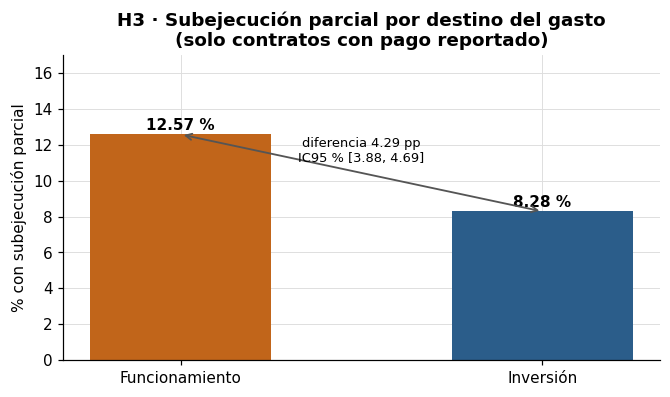

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.6))
cats = ["Funcionamiento", "Inversión"]
vals = [r3p["tasa_Funcionamiento"], r3p["tasa_Inversión"]]
ax.bar(cats, vals, color=[NARANJA, AZUL], width=0.5)
ax.set_ylabel("% con subejecución parcial")
ax.set_title("H3 · Subejecución parcial por destino del gasto\n"
             "(solo contratos con pago reportado)")
for i, v in enumerate(vals):
    ax.text(i, v + 0.25, f"{v:.2f} %", ha="center", fontweight="bold")
ax.annotate("", xy=(0, vals[0]), xytext=(1, vals[1]),
            arrowprops=dict(arrowstyle="<->", color="#555", lw=1.2))
ax.text(0.5, (vals[0] + vals[1]) / 2 + 0.6,
        f"diferencia {r3['valor_efecto']:.2f} pp\nIC95 % "
        f"[{r3['IC_lo']:.2f}, {r3['IC_hi']:.2f}]",
        ha="center", fontsize=8.5)
ax.set_ylim(0, max(vals) * 1.35)
print("figura:", guardar(fig, "h3_subejecucion_por_destino"))
plt.show()

**Resultado.** Se rechaza H₀. Los contratos de **funcionamiento** subejecutan más que los de
inversión: 12,57 % frente a 8,28 %, una diferencia de **4,29 pp** con IC 95 % [3,88; 4,69] que
excluye el cero con holgura. La V de Cramér es 0,069, es decir **despreciable** en términos de
Cohen: el efecto es real y bien estimado, pero pequeño.

**Matiz importante que se confirma más adelante.** Esto no convierte al destino del gasto en un
criterio de focalización. Sobre el objetivo completo, `desviacion`, la diferencia bruta va en
sentido contrario (15,24 % en inversión frente a 12,44 % en funcionamiento, notebook 02), y la
sección 12 muestra que cerca de la mitad de esa diferencia es composición —la inversión firma
contratos más caros— y que lo que queda no llega al umbral de relevancia en ningún rango de
valor. La diferencia de H3 describe un componente de la
desviación, no el objetivo que se focaliza.

---
## H4 - La adición difiere por orden de la entidad y por sector

**En palabras simples:** ¿alargar el plazo depende de si la entidad es nacional o territorial? ¿Y del sector?

**H₀:** la adición de plazo es independiente del orden (y del sector) de la entidad.
**H₁:** existe asociación.

*Rama del árbol:* categórica vs. categórica → **chi-cuadrado**.

Dos contrastes. Sirven además para ilustrar el problema central del notebook: **ambos son
significativos, pero ninguno tiene contenido práctico.**

In [8]:
for var in ["orden", "sector"]:
    r = prueba_chi2(M_TOTAL, var, "tiene_adicion", f"H4-{var}")
    RES.append(r)
    display(ficha_prueba(
        r,
        f"la adicion de plazo es independiente de {var}",
        f"la tasa de adicion difiere entre categorias de {var}",
        alpha=config.ALFA, umbral=config.V_MINIMA_UTIL))
    g = (M_TOTAL.groupby(agrupar_raras(M_TOTAL[var], 0.01), observed=True)["tiene_adicion"]
         .agg(n="size", tasa="mean").sort_values("tasa", ascending=False))
    g["tasa_%"] = (100 * g["tasa"]).round(2)
    print(g[["n", "tasa_%"]].head(8).to_string())
    print()

,Detalle
Paso,
1. Hipotesis nula (H0),la adicion de plazo es independiente de orden
1. Hipotesis alternativa (H1),la tasa de adicion difiere entre categorias de...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,46.8481 (gl = 2)
4. Valor p,6.715e-11
4. Tamano de efecto,V de Cramer = 0.0154 (despreciable)


                          n  tasa_%
orden                              
Nacional              96680    9.90
Territorial           97293    9.18
Corporación autónoma   2409    6.97



,Detalle
Paso,
1. Hipotesis nula (H0),la adicion de plazo es independiente de sector
1. Hipotesis alternativa (H1),la tasa de adicion difiere entre categorias de...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,"1,360.1853 (gl = 12)"
4. Valor p,5.326e-284
4. Tamano de efecto,V de Cramer = 0.0889 (despreciable)


                                      n  tasa_%
sector                                         
Trabajo                           14759   16.82
Cultura                            2792   10.57
Salud y protección social         22037   10.11
Otros                             10124   10.09
Educación nacional                10231    9.77
Servicio público                  37390    9.76
Defensa                           34585    9.72
Ambiente y desarrollo sostenible   8109    8.23



**Resultado.** Los dos rechazan H₀, pero con consecuencias opuestas:

- **`orden`**: p = 6,7 × 10⁻¹¹ —abrumadoramente significativo— y V = **0,0154**. Las tasas van
  del 9,90 % (Nacional) al 6,97 % (Corporación autónoma). Con 196.000 observaciones, tres puntos
  porcentuales de diferencia producen un p astronómicamente pequeño y **ninguna capacidad de
  focalización**. Es el ejemplo canónico de significancia sin relevancia.
- **`sector`**: V = **0,0889**, casi seis veces mayor. Trabajo adiciona plazo en el 16,8 % de
  los casos, casi el doble de la media (9,5 %). Sigue siendo «despreciable» según Cohen, pero el rango entre
  sectores sí es operativamente utilizable.

---
## H5 - Prorrogabilidad y pago adelantado se asocian a la adición

**En palabras simples:** ¿se alargan más los contratos que dicen «prorrogable»? ¿Y los que permiten pago adelantado?

**H₀:** la adición de plazo es independiente de que el contrato sea prorrogable (y de que
habilite pago adelantado).
**H₁:** existe asociación.

*Rama del árbol:* categórica vs. categórica → **chi-cuadrado**. Al ser tablas 2×2 se reporta
además la diferencia en puntos porcentuales con su IC 95 %, como en H3.

In [9]:
for var in ["el_contrato_puede_ser_prorrogado", "habilita_pago_adelantado"]:
    r = prueba_chi2(M_TOTAL, var, "tiene_adicion", f"H5-{var}", min_pct=0.0)
    RES.append(r)
    display(ficha_prueba(
        r,
        f"la adicion de plazo es independiente de {var}",
        f"la tasa de adicion difiere segun {var}",
        alpha=config.ALFA, umbral=config.V_MINIMA_UTIL))
    # Tamano de efecto en la escala del negocio: la diferencia en pp con su IC 95 %.
    rp = prueba_proporciones(M_TOTAL, var, "tiene_adicion", "Si", "No", f"H5-{var}")
    print(f"  adicion con {var} = Si: {rp['tasa_Si']:.2f} %   = No: {rp['tasa_No']:.2f} %")
    print(f"  diferencia = {rp['valor_efecto']:.2f} pp   "
          f"IC 95 % = [{rp['IC_lo']:.2f}, {rp['IC_hi']:.2f}]")
    print(r["tabla"].to_string())
    print()

,Detalle
Paso,
1. Hipotesis nula (H0),la adicion de plazo es independiente de el_con...
1. Hipotesis alternativa (H1),la tasa de adicion difiere segun el_contrato_p...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,628.5742 (gl = 1)
4. Valor p,1.021e-138
4. Tamano de efecto,V de Cramer = 0.0566 (despreciable)


  adicion con el_contrato_puede_ser_prorrogado = Si: 12.87 %   = No: 8.69 %
  diferencia = 4.19 pp   IC 95 % = [3.82, 4.55]
_y                                 False  True 
el_contrato_puede_ser_prorrogado               
No                                144253  13726
Si                                 33467   4945



,Detalle
Paso,
1. Hipotesis nula (H0),la adicion de plazo es independiente de habili...
1. Hipotesis alternativa (H1),la tasa de adicion difiere segun habilita_pago...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,1.2827 (gl = 1)
4. Valor p,2.574e-01
4. Tamano de efecto,V de Cramer = 0.0028 (despreciable)


  adicion con habilita_pago_adelantado = Si: 11.94 %   = No: 9.94 %
  diferencia = 2.00 pp   IC 95 % = [-1.47, 5.48]
_y                         False  True 
habilita_pago_adelantado               
No                        150899  16650
Si                           295     40



**Resultado — uno significativo y uno NO.**

- **`el_contrato_puede_ser_prorrogado`**: significativo. Los contratos marcados como prorrogables
  reciben adición en el 12,87 % de los casos, frente al 8,69 % de los demás: **4,19 puntos
  porcentuales** más, con IC 95 % [3,82; 4,55]. Coherente, aunque en parte tautológico: la
  prorrogabilidad es precisamente el permiso para adicionar. Su V de Cramér (0,057) queda por
  debajo del umbral: el efecto es real, pero pequeño.

  Con un matiz que es un hallazgo en sí mismo: **13.726 contratos recibieron adición de plazo
  pese a estar marcados como NO prorrogables** (la regla R14 del notebook 01). O el campo está
  mal capturado, o se adicionó plazo sin habilitación contractual. En cualquiera de los dos
  casos es un criterio de alerta para control interno.

- **`habilita_pago_adelantado`**: **p = 0,257 — NO significativo**, V = 0,003. Los contratos que
  habilitan pago adelantado reciben adición en el 11,94 % de los casos, frente al 9,94 %: 2,00
  puntos más, pero con IC 95 % [−1,47; 5,48], que **contiene el cero**. No se rechaza H₀: aun sin
  ninguna relación real, una diferencia así aparecería por casualidad una de cada cuatro veces.

  La razón no es que no exista efecto, sino que **no hay datos para detectarlo**: solo 335
  contratos (0,2 % de los que tienen el campo diligenciado) habilitan pago adelantado. El
  intervalo es tan ancho que admite desde «ningún efecto» hasta 5,5 puntos más de adición. Es un
  resultado no significativo por falta de potencia, y así debe reportarse: **la ausencia de
  evidencia no es evidencia de ausencia.**

---
## H6 - La magnitud de los días adicionados difiere entre sectores

**En palabras simples:** entre los contratos que sí se alargaron, ¿el número de días añadidos cambia según el sector?

Las hipótesis anteriores preguntan *si* hay adición. Esta pregunta *cuánta*, condicionada a que
haya habido.

**H₀:** la media de días adicionados es igual en todos los sectores.
**H₁:** al menos un sector difiere.

*Rama del árbol:* numérica vs. categórica de más de dos grupos → **ANOVA**. Se usa la variante
de **Welch**, que no exige varianzas iguales: aquí la razón entre la varianza mayor y la menor
supera el factor 12, así que forzar el ANOVA clásico sería elegir la prueba sin validar su
supuesto. Welch es además la misma elección que hace el ejemplo trabajado del curso.

`dias_adicionados` es un conteo muy asimétrico, de modo que el ANOVA se apoya en el teorema
central del límite —con 34 observaciones en el grupo más pequeño y 16.678 en total— y se
acompaña de la verificación no paramétrica correspondiente.

In [10]:
con_adicion = M_TOTAL[M_TOTAL["tiene_adicion"]]
r6 = prueba_anova(con_adicion, "dias_adicionados", "sector", min_grupo=30,
                  welch=True, hipotesis="H6")
RES.append(r6)
display(ficha_prueba(
    r6,
    "la media de dias adicionados es igual en todos los sectores",
    "al menos un sector difiere en la magnitud de la adicion",
    alpha=config.ALFA, umbral=config.ETA2_MINIMO_UTIL))

print(f"grupos comparados        : {r6['categorias']} sectores con n >= 30")
print(f"grados de libertad       : {r6['gl']:.0f} y {r6['gl_den']:.1f} (Welch)")
print(f"razon de varianzas       : {r6['razon_varianzas']:.1f}x  "
      f"-> el ANOVA clasico no seria aplicable")
print(f"asimetria maxima         : {r6['asimetria_max']:.2f}  "
      f"-> se apoya en el TCL, no en normalidad de los datos")

med = (con_adicion.groupby("sector", observed=True)["dias_adicionados"]
       .agg(n="size", media="mean", mediana="median",
            p75=lambda s: s.quantile(0.75))
       .query("n >= 30").sort_values("media", ascending=False))
display(med.head(12).round(1))
print(f"media global entre contratos con adicion   : "
      f"{con_adicion['dias_adicionados'].mean():.1f} dias")
print(f"mediana global entre contratos con adicion : "
      f"{con_adicion['dias_adicionados'].median():.0f} dias")

# --- Robustez: la alternativa no parametrica de ANOVA ---
r6k = prueba_kruskal(con_adicion, "sector", "dias_adicionados", 30, "H6-rob")
ROB.append(r6k)
print(f"\nVerificacion de robustez")
print(f"  Kruskal-Wallis  H = {r6k['estadistico']:,.1f}   p = {r6k['p']:.3e}   "
      f"epsilon cuadrado = {r6k['valor_efecto']:.4f}")
print(f"  ANOVA de Welch  F = {r6['estadistico']:,.2f}   p = {r6['p']:.3e}   "
      f"eta cuadrado = {r6['valor_efecto']:.4f}")
print("  -> ambas rechazan H0 y ambas miden un efecto pequeno: la asimetria no")
print("     altera la conclusion, que es justo lo que habia que comprobar")

,Detalle
Paso,
1. Hipotesis nula (H0),la media de dias adicionados es igual en todos...
1. Hipotesis alternativa (H1),al menos un sector difiere en la magnitud de l...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,ANOVA de Welch
3. Supuesto a validar,n >= 30 por grupo (TCL); Welch no exige varian...
3. Verificacion del supuesto,cumple
4. Estadistico,30.2898 (gl = 22)
4. Valor p,1.265e-94
4. Tamano de efecto,eta cuadrado = 0.0318 (pequeno)


grupos comparados        : 23 sectores con n >= 30
grados de libertad       : 22 y 978.9 (Welch)
razon de varianzas       : 12.6x  -> el ANOVA clasico no seria aplicable
asimetria maxima         : 6.05  -> se apoya en el TCL, no en normalidad de los datos


,n,media,mediana,p75
sector,,,,
Ciencia tecnología,47,139.7,74.0,233.5
Interior,129,85.2,35.0,105.0
"Vivienda, ciudad y territorio",149,82.4,31.0,90.0
Relaciones exteriores,34,79.1,77.0,111.8
Minas y energía,155,74.1,46.0,89.5
Hacienda y crédito público,146,71.2,41.5,91.8
Presidencia de la república,54,65.4,46.0,92.0
Transporte,365,64.6,34.0,87.0
Planeación,91,63.1,31.0,72.0


media global entre contratos con adicion   : 53.7 dias
mediana global entre contratos con adicion : 31 dias

Verificacion de robustez
  Kruskal-Wallis  H = 603.6   p = 1.506e-113   epsilon cuadrado = 0.0349
  ANOVA de Welch  F = 30.29   p = 1.265e-94   eta cuadrado = 0.0318
  -> ambas rechazan H0 y ambas miden un efecto pequeno: la asimetria no
     altera la conclusion, que es justo lo que habia que comprobar


figura: reports/figures/h6_magnitud_adicion_por_sector.png


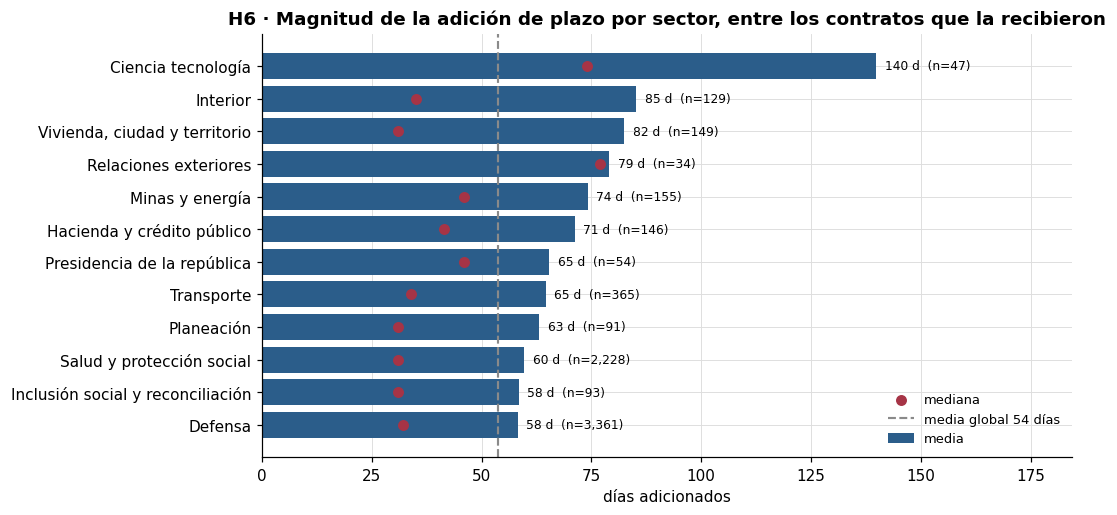

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 5))
# El ANOVA contrasta medias, asi que la figura muestra medias. Se marca ademas
# la mediana de cada sector: la distancia entre ambas es la asimetria que
# obligo a acompanar el ANOVA con la verificacion de Kruskal-Wallis.
top = med.head(12).sort_values("media")
ax.barh(top.index.astype(str), top["media"], color=AZUL, label="media")
ax.scatter(top["mediana"], range(len(top)), color=ROJO, s=38, zorder=3,
           label="mediana")
ax.axvline(con_adicion["dias_adicionados"].mean(), color=GRIS, ls="--", lw=1.4,
           label=f"media global {con_adicion['dias_adicionados'].mean():.0f} días")
ax.set_xlabel("días adicionados")
ax.set_title("H6 · Magnitud de la adición de plazo por sector, "
             "entre los contratos que la recibieron")
ax.legend(loc="lower right", fontsize=8.5)
for i, (v, n) in enumerate(zip(top["media"], top["n"])):
    ax.text(v + 2, i, f"{v:.0f} d  (n={n:,})", va="center", fontsize=8)
ax.set_xlim(0, top["media"].max() * 1.32)
print("figura:", guardar(fig, "h6_magnitud_adicion_por_sector"))
plt.show()


**Resultado.** Se rechaza H₀ (ANOVA de Welch, p = 1,3 × 10⁻⁹⁴), con η² = **0,032**: el sector
explica apenas el 3,2 % de la variabilidad en la magnitud de la adición. Kruskal-Wallis llega a
lo mismo (ε² = 0,035). Significativo y de efecto pequeño, otra vez.

Lo relevante es la escala absoluta: la mediana global es de **31 días** y los sectores más
extremos superan los **74 días**. No son prórrogas marginales, son entre uno y dos meses y medio
de retraso en la entrega del bien a la ciudadanía.

---
## H7 - Control: el género del representante legal y la desviación

**En palabras simples:** ¿el género del representante legal tiene que ver con la desviación? Es la pregunta de control, como el placebo de un experimento médico: se espera un «no», y si el género saliera importante querría decir que el método detecta cosas que no existen.

**H₀:** la desviación es independiente del género del representante legal.
**H₁:** existe asociación.

*Rama del árbol:* categórica vs. categórica → **chi-cuadrado**.

Esta hipótesis se incluye **sin ninguna expectativa de mecanismo causal**. Su función es
calibrar: mostrar qué le hace un n de 160.000 al valor p cuando la asociación subyacente es
trivial.

In [12]:
r7 = prueba_chi2(M_TOTAL, "genero_representante_legal", "desviacion", "H7")
RES.append(r7)
display(ficha_prueba(
    r7,
    "la desviacion es independiente del genero del representante legal",
    "existe asociacion entre genero y desviacion",
    alpha=config.ALFA, umbral=config.V_MINIMA_UTIL))

tab = r7["tabla"]
tasas7 = (100 * tab[True] / tab.sum(axis=1)).round(2)
display(pd.DataFrame({"n": tab.sum(axis=1), "tasa_%": tasas7}))
print(f"rango entre categorias: {tasas7.max() - tasas7.min():.2f} puntos porcentuales")
print("Significativo y a la vez irrelevante. Queda excluido de todo criterio.")

,Detalle
Paso,
1. Hipotesis nula (H0),la desviacion es independiente del genero del ...
1. Hipotesis alternativa (H1),existe asociacion entre genero y desviacion
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,14.0473 (gl = 2)
4. Valor p,8.906e-04
4. Tamano de efecto,V de Cramer = 0.0094 (despreciable)


,n,tasa_%
genero_representante_legal,,
Hombre,88209,13.84
Mujer,70285,13.41
Otro,2075,15.81


rango entre categorias: 2.40 puntos porcentuales
Significativo y a la vez irrelevante. Queda excluido de todo criterio.


**Resultado — el más instructivo del notebook.** p = **0,0009**: si el género no tuviera
nada que ver, una diferencia así aparecería por casualidad menos de una vez en mil. Es
formalmente significativo. Pero la V de Cramér es **0,0094** y la
diferencia entre hombres (13,84 %) y mujeres (13,41 %) es de **0,43 puntos porcentuales**.

Si el criterio de decisión fuera el valor p, habría que concluir que el género del representante
legal «predice» la desviación contractual y usarlo para focalizar supervisión. Sería un
disparate: estadístico, operativo y ético.

**Esto es exactamente lo que el tamaño de efecto sirve para evitar.** Con n grande, la pregunta
«¿es significativo?» está mal planteada; la pregunta correcta es «¿de qué tamaño es el efecto y
alcanza para decidir algo?». Aquí la respuesta es no. **Esta variable queda excluida de todo
criterio de focalización.**

---
## H8 - El fallo de reporte de pagos se concentra por orden y sector

**En palabras simples:** ¿dejar de registrar pagos se concentra en ciertos tipos de entidad o sectores?

**H₀:** la ausencia de pago reportado es independiente del orden (y del sector) de la entidad.
**H₁:** existe asociación.

*Rama del árbol:* categórica vs. categórica → **chi-cuadrado**.

El notebook 01 identificó una zona ciega: 107.452 contratos (54,71 %) sin ningún pago
registrado. En vez de descartarla, se la interroga. Para una oficina de control interno, un
contrato con el plazo vencido y sin registro de pago **es** un problema de supervisión.

In [13]:
for var in ["orden", "sector"]:
    r = prueba_chi2(M_TOTAL, var, "pago_cero", f"H8-{var}")
    RES.append(r)
    display(ficha_prueba(
        r,
        f"la ausencia de pago reportado es independiente de {var}",
        f"el fallo de reporte se concentra en ciertas categorias de {var}",
        alpha=config.ALFA, umbral=config.V_MINIMA_UTIL))

g8 = (M_TOTAL.groupby("sector", observed=True)["pago_cero"]
      .agg(n="size", tasa="mean").query("n >= 500").sort_values("tasa", ascending=False))
g8["tasa_%"] = (100 * g8["tasa"]).round(2)
display(g8[["n", "tasa_%"]].head(14))

,Detalle
Paso,
1. Hipotesis nula (H0),la ausencia de pago reportado es independiente...
1. Hipotesis alternativa (H1),el fallo de reporte se concentra en ciertas ca...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,263.1325 (gl = 2)
4. Valor p,7.270e-58
4. Tamano de efecto,V de Cramer = 0.0366 (despreciable)


,Detalle
Paso,
1. Hipotesis nula (H0),la ausencia de pago reportado es independiente...
1. Hipotesis alternativa (H1),el fallo de reporte se concentra en ciertas ca...
2. Nivel de significancia,alfa = 0.05 (fijado antes de ver los datos)
3. Prueba elegida,chi2 de independencia
3. Supuesto a validar,frecuencia esperada >= 5 en todas las celdas
3. Verificacion del supuesto,cumple
4. Estadistico,"8,479.8841 (gl = 12)"
4. Valor p,< 1e-300
4. Tamano de efecto,V de Cramer = 0.2221 (pequeno)


,n,tasa_%
sector,,
Salud y protección social,22037,74.18
Interior,1172,72.87
Agricultura,1254,72.49
Transporte,4655,70.14
Minas y energía,1025,64.49
"Vivienda, ciudad y territorio",1497,63.99
Inclusión social y reconciliación,836,63.88
Tecnologías de la información y las comunicaciones,638,61.60
Industria,1807,61.37


figura: reports/figures/h8_zona_ciega_por_sector.png


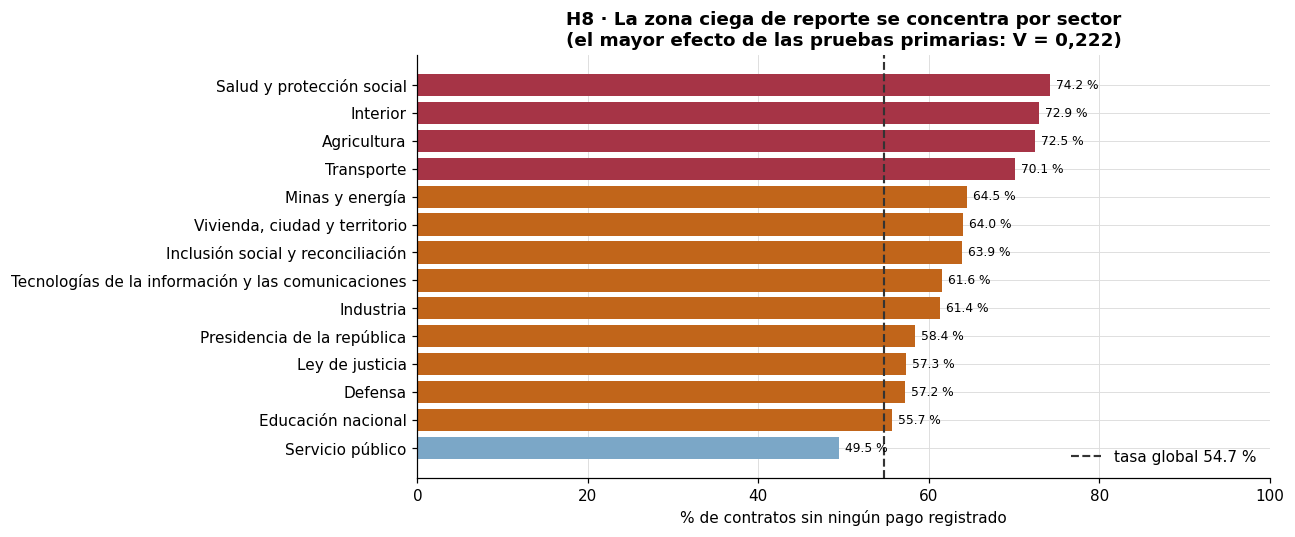

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
t8 = g8.head(14).sort_values("tasa_%")
base8 = 100 * M_TOTAL["pago_cero"].mean()
colores = [ROJO if v > 70 else (NARANJA if v > base8 else AZUL_CLARO)
           for v in t8["tasa_%"]]
ax.barh(t8.index.astype(str), t8["tasa_%"], color=colores)
ax.axvline(base8, color="#333", ls="--", lw=1.4, label=f"tasa global {base8:.1f} %")
ax.set_xlabel("% de contratos sin ningún pago registrado")
ax.set_title("H8 · La zona ciega de reporte se concentra por sector\n"
             "(el mayor efecto de las pruebas primarias: V = 0,222)")
ax.legend(loc="lower right")
for i, (v, n) in enumerate(zip(t8["tasa_%"], t8["n"])):
    ax.text(v + 0.7, i, f"{v:.1f} %", va="center", fontsize=8)
ax.set_xlim(0, 100)
print("figura:", guardar(fig, "h8_zona_ciega_por_sector"))
plt.show()

**Resultado.** Se rechaza H₀ en ambos casos, y aquí aparece **el tamaño de efecto más grande de
las pruebas primarias**: V = **0,222** para sector, un orden de magnitud por encima de casi todo
lo demás y, junto con H1, el único contraste que sale de la categoría «despreciable» de Cohen.
La matriz exploratoria de la sección 13 encuentra fuera del plan uno del mismo tamaño.

Salud y protección social no registra pago en el **74,2 %** de sus contratos; Interior el 72,9 %;
Agricultura el 72,5 %. Frente a una media del 54,7 %.

**Lectura de negocio, y es contraintuitiva.** La sección 12 compara la desviación de cada sector
con la que anticiparía su mezcla de modalidades y valores. Transporte, que no registra pago en el
70,1 % de sus contratos, se desvía bastante menos de lo esperado (10,8 % frente a 14,3 %), y
Trabajo, el sector que mejor reporta, bastante más (19,3 % frente a 13,3 %). La explicación es
que **no se puede detectar subejecución donde no hay datos de pago**: los sectores que peor
reportan pueden parecer más limpios de lo que son. Es un sesgo de medición que invierte el orden
de prioridades si se lee una tasa baja como cumplimiento.

Por eso la recomendación del informe final separa dos frentes: focalizar la supervisión de
*ejecución* con la regla de valor y modalidad, y abrir un frente distinto de **calidad del reporte** dirigido a los
sectores de esta lista.

---
## 8. Validación de supuestos

El paso 3 del procedimiento de contraste no termina al elegir la prueba: exige validar sus
supuestos. Esta sección los recoge en un solo sitio, con el diagnóstico de cada uno, para que
ninguna prueba quede reportada sin declarar sobre qué se apoya.

In [15]:
filas = []
for r in RES:
    detalle = []
    if r.get("min_esperada") is not None:
        detalle.append(f"frecuencia esperada minima = {r['min_esperada']:,.1f}")
    if r.get("razon_varianzas") is not None:
        detalle.append(f"razon de varianzas = {r['razon_varianzas']:.1f}x")
    if r.get("asimetria_max") is not None:
        detalle.append(f"asimetria maxima = {r['asimetria_max']:.2f}")
    if r.get("asimetria_a") is not None:
        detalle.append(f"asimetria de los grupos = "
                       f"{r['asimetria_a']:+.2f} / {r['asimetria_b']:+.2f}")
    if r.get("min_grupo_n") is not None:
        detalle.append(f"grupo mas pequeno = {r['min_grupo_n']:,} obs.")
    if r.get("n_a") is not None:
        detalle.append(f"grupos de {r['n_a']:,} y {r['n_b']:,} obs.")
    filas.append({"hipotesis": r.get("hipotesis"), "prueba": r.get("prueba"),
                  "supuesto": r.get("supuesto", "no declarado"),
                  "cumple": "si" if r.get("supuesto_ok") else "NO",
                  "diagnostico": "; ".join(detalle)})

sup = pd.DataFrame(filas)
display(sup)
sup.to_csv(config.TABLAS / "validacion_supuestos.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/validacion_supuestos.csv")

incumplen = sup.loc[sup["cumple"] == "NO", "hipotesis"].tolist()
print(f"\npruebas con algun supuesto sin cumplir: {incumplen if incumplen else 'ninguna'}")
print("\nDos supuestos merecen comentario explicito:")
print("  H6  las varianzas entre sectores difieren por un factor superior a 12, asi que")
print("      se usa Welch en lugar del ANOVA clasico, y la asimetria elevada se cubre")
print("      con la verificacion de Kruskal-Wallis.")
print("  H2b la distribucion de log10(valor) no es normal, pero el Z test no lo exige:")
print("      lo que necesita es normalidad de la diferencia de medias, que el TCL")
print(f"      garantiza con {r2b['n_a']:,} y {r2b['n_b']:,} observaciones por grupo.")

,hipotesis,prueba,supuesto,cumple,diagnostico
0,H1,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,frecuencia esperada minima = 22.4
1,H2,Correlacion de Pearson,ambas variables numericas; Spearman no exige r...,si,
2,H2b,Z test de dos medias,n >= 30 por grupo (TCL),si,asimetria de los grupos = +0.11 / -0.78; grupo...
3,H3,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,"frecuencia esperada minima = 4,333.6"
4,H4-orden,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,frecuencia esperada minima = 229.0
5,H4-sector,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,frecuencia esperada minima = 175.3
6,H5-el_contrato_puede_ser_prorrogado,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,"frecuencia esperada minima = 3,651.8"
7,H5-habilita_pago_adelantado,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,frecuencia esperada minima = 33.3
8,H6,ANOVA de Welch,n >= 30 por grupo (TCL); Welch no exige varian...,si,razon de varianzas = 12.6x; asimetria maxima =...
9,H7,chi2 de independencia,frecuencia esperada >= 5 en todas las celdas,si,frecuencia esperada minima = 283.8


escrito: reports/tablas/validacion_supuestos.csv

pruebas con algun supuesto sin cumplir: ninguna

Dos supuestos merecen comentario explicito:
  H6  las varianzas entre sectores difieren por un factor superior a 12, asi que
      se usa Welch en lugar del ANOVA clasico, y la asimetria elevada se cubre
      con la verificacion de Kruskal-Wallis.
  H2b la distribucion de log10(valor) no es normal, pero el Z test no lo exige:
      lo que necesita es normalidad de la diferencia de medias, que el TCL
      garantiza con 26,603 y 169,788 observaciones por grupo.


---
## 9. Resumen de las doce pruebas primarias

La tabla reúne las doce pruebas primarias con su valor p, su veredicto y su tamaño de efecto. Una
prueba es significativa si su valor p queda por debajo de 0,05, el nivel fijado antes de ver los
datos. Las verificaciones de robustez se guardan en una tabla aparte: no son pruebas nuevas, sino
la misma pregunta hecha con otra herramienta.

In [16]:
# Las doce pruebas primarias. Una prueba es significativa si su valor p queda por
# debajo de alfa, fijado en config antes de ver los datos.
tabla_res = pd.DataFrame([{k: v for k, v in r.items() if k != "tabla"} for r in RES])
tabla_res["significativo"] = tabla_res["p"] < config.ALFA
cols = ["hipotesis", "variable", "objetivo", "prueba", "n", "p", "significativo",
        "efecto", "valor_efecto", "IC_lo", "IC_hi", "magnitud", "supuesto_ok"]
resumen = tabla_res[[c for c in cols if c in tabla_res.columns]].copy()
resumen["p"] = resumen["p"].map(lambda x: f"{x:.3e}")
for c in ("valor_efecto", "IC_lo", "IC_hi"):
    if c in resumen.columns:
        resumen[c] = resumen[c].round(4)
display(resumen)

resumen.to_csv(config.TABLAS / "pruebas_hipotesis.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/pruebas_hipotesis.csv")

# Las verificaciones de robustez se guardan aparte, para que quede claro que no
# son pruebas primarias.
rob = pd.DataFrame([{k: v for k, v in r.items() if k != "tabla"} for r in ROB])
rob_cols = [c for c in ["hipotesis", "variable", "objetivo", "prueba", "n", "p",
                        "efecto", "valor_efecto"] if c in rob.columns]
rob = rob[rob_cols]
display(rob)
rob.to_csv(config.TABLAS / "pruebas_robustez.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/pruebas_robustez.csv")

print(f"\npruebas primarias: {len(tabla_res)}")
print(f"significativas (p < {config.ALFA}): {tabla_res['significativo'].sum()} "
      f"de {len(tabla_res)}")
no_sig = tabla_res.loc[~tabla_res["significativo"], "hipotesis"].tolist()
print(f"NO significativas: {no_sig}")

# Inventario de pruebas efectivamente usadas, para verificar la conformidad.
print("\nPruebas primarias utilizadas:")
for nombre, k in tabla_res["prueba"].value_counts().items():
    print(f"  {k:>2}x  {nombre}")

,hipotesis,variable,objetivo,prueba,n,p,significativo,efecto,valor_efecto,IC_lo,IC_hi,magnitud,supuesto_ok
0,H1,modalidad_de_contratacion,tiene_adicion,chi2 de independencia,196391,0.000e+00,True,V de Cramer,0.1444,NaN,NaN,pequeno,True
1,H2,decil,tasa_%,Correlacion de Pearson,10,1.834e-05,True,r de Pearson,0.9541,0.8127,0.9894,NaN,True
2,H2b,log_valor,desviacion,Z test de dos medias,196391,0.000e+00,True,diferencia de medias,0.4488,0.4383,0.4593,NaN,True
3,H3,destino_gasto,subejecucion_parcial,chi2 de independencia,88142,1.685e-94,True,diferencia de proporciones (pp),4.2852,3.8844,4.6861,NaN,True
4,H4-orden,orden,tiene_adicion,chi2 de independencia,196382,6.715e-11,True,V de Cramer,0.0154,NaN,NaN,despreciable,True
5,H4-sector,sector,tiene_adicion,chi2 de independencia,171917,5.326e-284,True,V de Cramer,0.0889,NaN,NaN,despreciable,True
6,H5-el_contrato_puede_ser_prorrogado,el_contrato_puede_ser_prorrogado,tiene_adicion,chi2 de independencia,196391,1.021e-138,True,V de Cramer,0.0566,NaN,NaN,despreciable,True
7,H5-habilita_pago_adelantado,habilita_pago_adelantado,tiene_adicion,chi2 de independencia,167884,2.574e-01,False,V de Cramer,0.0028,NaN,NaN,despreciable,True
8,H6,sector,dias_adicionados,ANOVA de Welch,16678,1.265e-94,True,eta cuadrado,0.0318,NaN,NaN,pequeno,True
9,H7,genero_representante_legal,desviacion,chi2 de independencia,160569,8.906e-04,True,V de Cramer,0.0094,NaN,NaN,despreciable,True


escrito: reports/tablas/pruebas_hipotesis.csv


,hipotesis,variable,objetivo,prueba,n,p,efecto,valor_efecto
0,H2-rob,decil,tasa_%,Correlacion de Spearman,10,6.646897e-64,rho de Spearman,0.999999
1,H2-rob-fila,decil_valor,desviacion,Spearman (tendencia),196391,0.000000e+00,rho de Spearman,0.184202
2,H2b-rob,log_valor,desviacion,Mann-Whitney U,196391,0.000000e+00,delta de Cliff,0.315644
3,H6-rob,sector,dias_adicionados,Kruskal-Wallis,16678,1.505949e-113,epsilon cuadrado,0.034922


escrito: reports/tablas/pruebas_robustez.csv

pruebas primarias: 12
significativas (p < 0.05): 11 de 12
NO significativas: ['H5-habilita_pago_adelantado']

Pruebas primarias utilizadas:
   9x  chi2 de independencia
   1x  Correlacion de Pearson
   1x  Z test de dos medias
   1x  ANOVA de Welch


**Once de las doce pruebas son significativas.** Los valores p son tan extremos —varios por
debajo de 10⁻¹⁰⁰— que el veredicto no depende de dónde se ponga el umbral: la significativa más
cercana a 0,05 es H7, con 0,0009. El único resultado no significativo es
`habilita_pago_adelantado` (H5), con p = 0,257, por falta de potencia.

Esto refuerza el argumento de fondo: **con este tamaño de muestra, el valor p no es lo que
protege del error.** Lo que protege es exigir un tamaño de efecto mínimo, que es lo que muestra
la sección siguiente.

---
## 10. Significancia frente a relevancia

La síntesis gráfica del argumento metodológico del notebook. Se grafican los **nueve contrastes
chi-cuadrado**, que son los que comparten una misma escala de efecto y por tanto los únicos
comparables en un plano. Los otros tres —la correlación de H2, el Z test de H2b y el ANOVA de
H6— miden efectos en unidades distintas y se discuten en su propia sección.

En palabras simples: *significativo* quiere decir «difícil de explicar como casualidad», y
*relevante*, «lo bastante grande para cambiar una decisión». Con 196.000 contratos lo primero es
casi automático; lo segundo no.

(2 pruebas con p < 1e-300, topadas en el eje)

figura: reports/figures/significancia_vs_efecto.png


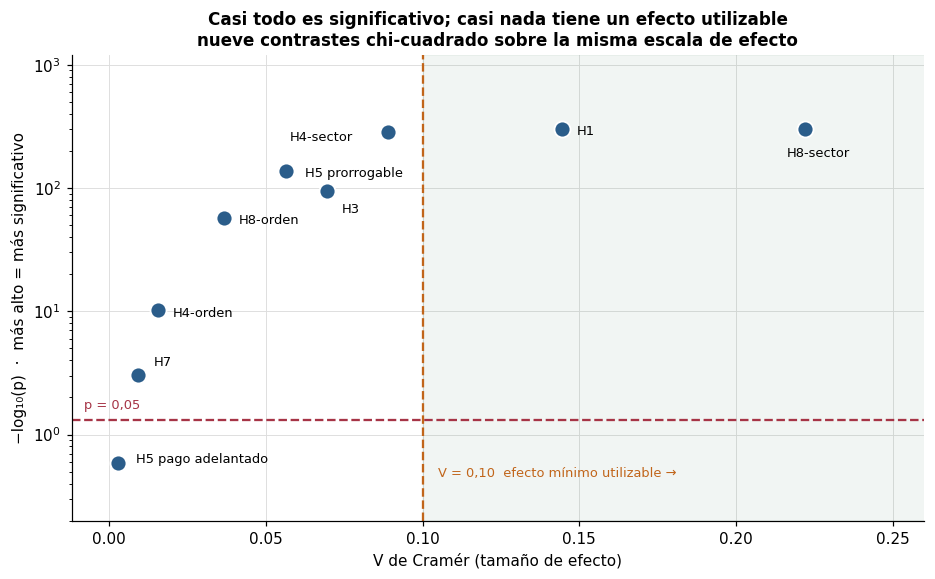

Cuadrante util (V >= 0,10): ['H1', 'H8-sector']
Significativas pero con efecto despreciable: ['H3', 'H4-orden', 'H4-sector', 'H5-el_contrato_puede_ser_prorrogado', 'H7', 'H8-orden']


In [17]:
# Los nueve contrastes chi-cuadrado, que son los unicos que comparten escala
# de efecto. H3 reporta su efecto en puntos porcentuales, pero su V de Cramer
# quedo guardada aparte para que pueda compararse aqui con los demas.
sig = tabla_res.copy()
sig["v"] = sig["valor_efecto"].where(sig["efecto"] == "V de Cramer")
if "v_cramer" in sig.columns:
    sig["v"] = sig["v"].fillna(sig["v_cramer"])
sig = sig.dropna(subset=["v"]).copy()
sig["log_p"] = -np.log10(sig["p"].clip(lower=1e-300))

TOPE = 300          # los p por debajo de 1e-300 se topan para que quepan en el eje
sig["log_p"] = sig["log_p"].clip(upper=TOPE)
n_topados = int((sig["p"] <= 1e-300).sum())

fig, ax = plt.subplots(figsize=(10, 5.5))
# Region utilizable: significativo Y con efecto no despreciable.
ax.axvspan(0.10, 0.30, color=VERDE, alpha=0.07)
ax.scatter(sig["v"], sig["log_p"], s=110, color=AZUL, zorder=3,
           edgecolor="white", linewidth=1.2)

# Desplazamientos manuales para que ninguna etiqueta tape a otra.
OFFSETS = {"H1": (10, -4), "H8-sector": (-12, -18), "H4-sector": (-64, -6),
           "H5-el_contrato_puede_ser_prorrogado": (12, -4), "H8-orden": (10, -4),
           "H4-orden": (10, -4), "H7": (10, 6), "H3": (10, -14),
           "H5-habilita_pago_adelantado": (12, 0)}
for _, row in sig.iterrows():
    etq = row["hipotesis"].replace("H5-el_contrato_puede_ser_prorrogado", "H5 prorrogable") \
                          .replace("H5-habilita_pago_adelantado", "H5 pago adelantado")
    ax.annotate(etq, (row["v"], row["log_p"]),
                textcoords="offset points",
                xytext=OFFSETS.get(row["hipotesis"], (9, 5)), fontsize=8.5)

ax.axvline(0.10, color=NARANJA, ls="--", lw=1.5)
ax.axhline(-np.log10(0.05), color=ROJO, ls="--", lw=1.5)
ax.set_yscale("log")
ax.set_ylim(0.2, TOPE * 4)
ax.set_xlim(-0.012, 0.26)
ax.text(0.105, 0.45, "V = 0,10  efecto mínimo utilizable →", fontsize=8.5,
        color=NARANJA)
ax.text(-0.008, -np.log10(0.05) * 1.25, "p = 0,05", fontsize=8.5, color=ROJO)
ax.set_xlabel("V de Cramér (tamaño de efecto)")
ax.set_ylabel("−log₁₀(p)  ·  más alto = más significativo")
ax.set_title("Casi todo es significativo; casi nada tiene un efecto utilizable\n"
             "nueve contrastes chi-cuadrado sobre la misma escala de efecto",
             fontsize=11)
print(f"({n_topados} pruebas con p < 1e-300, topadas en el eje)")
print("figura:", guardar(fig, "significancia_vs_efecto"))
plt.show()

print("Cuadrante util (V >= 0,10):",
      sig.loc[sig["v"] >= 0.10, "hipotesis"].tolist())
print("Significativas pero con efecto despreciable:",
      sig.loc[(sig["v"] < 0.10) & sig["significativo"], "hipotesis"].tolist())

Los nueve contrastes caen por encima de la línea de significancia, varios a alturas absurdas.
Pero solo **H1** (modalidad) y **H8-sector** (zona ciega) superan el umbral de efecto utilizable
que se fijó antes de ver los datos. Las demás son ciertas y, a la vez, inútiles para focalizar.

Sumando los tres contrastes que usan otra métrica, **cinco de las doce pruebas** superan su
umbral: H1, H2, H2b, H3 y H8-sector. De esas cinco, H3 no se traduce en criterio —sobre la
desviación, el efecto propio del destino del gasto es pequeño y no llega al umbral en
ningún rango de valor (§12)— y H8-sector
pertenece a un frente de acción distinto, de modo que **el criterio de
focalización se sostiene sobre dos cosas: el valor del contrato y la modalidad**.

---
## 11. Análisis multivariado descriptivo: valor × modalidad

Las dos variables con mayor tamaño de efecto, cruzadas. Muestra si se refuerzan o si una absorbe
a la otra.

figura: reports/figures/heatmap_modalidad_x_valor.png


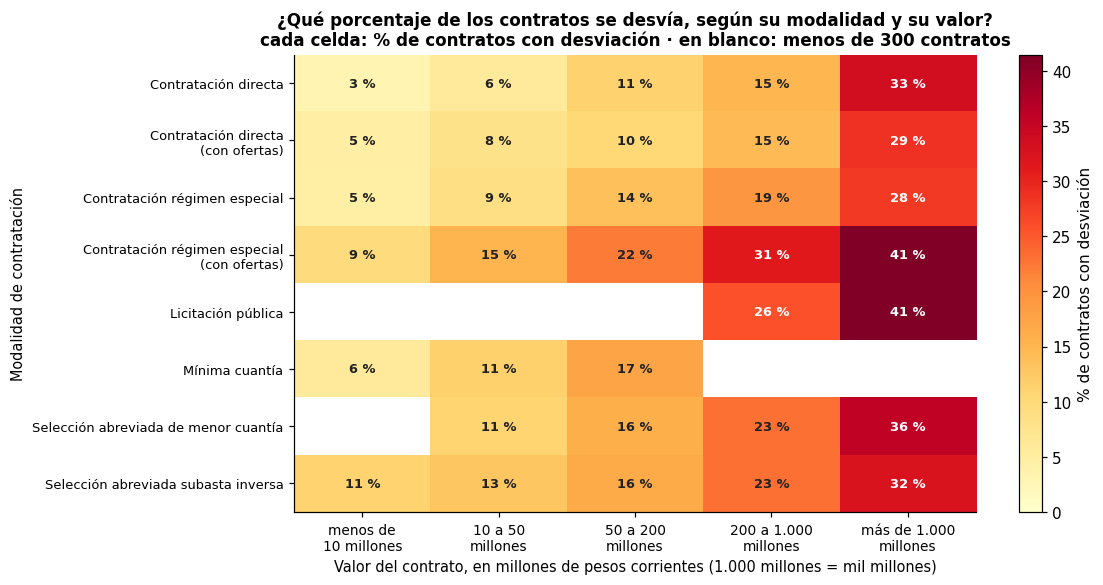

banda_valor,< 10 M,10–50 M,50–200 M,200–1.000 M,> 1.000 M
modalidad,,,,,
Contratación directa,3.2,5.9,11.2,14.9,33.5
Contratación directa (con ofertas),4.8,7.9,10.3,14.5,28.7
Contratación régimen especial,4.6,8.7,13.7,19.3,27.9
Contratación régimen especial (con ofertas),9.5,15.1,22.1,31.4,41.4
Licitación pública,NaN,NaN,NaN,25.7,41.5
Mínima cuantía,5.8,11.4,17.4,NaN,NaN
Otros,NaN,NaN,NaN,NaN,NaN
Selección abreviada de menor cuantía,NaN,11.0,16.0,23.0,35.7
Selección abreviada subasta inversa,11.1,12.9,16.4,23.0,32.2


In [18]:
CORTES = [0, 10e6, 50e6, 200e6, 1000e6, np.inf]
ETIQ = ["< 10 M", "10–50 M", "50–200 M", "200–1.000 M", "> 1.000 M"]
dh = M_TOTAL.copy()
dh["banda_valor"] = pd.cut(dh["valor_del_contrato"], CORTES, labels=ETIQ, right=False)
dh["modalidad"] = agrupar_raras(dh["modalidad_de_contratacion"], 0.01)

piv = dh.pivot_table(index="modalidad", columns="banda_valor", values="desviacion",
                     aggfunc=["mean", "size"], observed=True)
# Sin redondear aqui: la figura redondea una sola vez al escribir cada celda.
# Redondear antes a un decimal convertia 41,46 en 41,5 y luego en 42.
tasa = 100 * piv["mean"]
cuenta = piv["size"]
tasa_v = tasa.where(cuenta >= 300)      # se ocultan celdas sin volumen suficiente

# En la figura se omiten las filas sin ninguna celda con volumen (hoy, «Otros»).
fig_v = tasa_v.dropna(how="all")
# El eje horizontal es el valor del contrato: M = millones de pesos corrientes.
ETIQ_EJE = ["menos de\n10 millones", "10 a 50\nmillones", "50 a 200\nmillones",
            "200 a 1.000\nmillones", "más de 1.000\nmillones"]

fig, ax = plt.subplots(figsize=(10, 5.4))
im = ax.imshow(fig_v.values.astype(float), cmap="YlOrRd", aspect="auto",
               vmin=0, vmax=np.nanmax(fig_v.values.astype(float)))
ax.set_xticks(range(len(fig_v.columns)), ETIQ_EJE, fontsize=9)
ax.set_yticks(range(len(fig_v.index)),
              [str(i).replace(" (con ofertas)", "\n(con ofertas)") for i in fig_v.index],
              fontsize=8.5)
for i in range(fig_v.shape[0]):
    for j in range(fig_v.shape[1]):
        v = fig_v.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f} %", ha="center", va="center", fontsize=8.5,
                    color="white" if v > 25 else "#222", fontweight="bold")
ax.set_xlabel("Valor del contrato, en millones de pesos corrientes "
              "(1.000 millones = mil millones)", fontsize=9.5)
ax.set_ylabel("Modalidad de contratación", fontsize=9.5)
ax.set_title("¿Qué porcentaje de los contratos se desvía, según su modalidad y su valor?\n"
             "cada celda: % de contratos con desviación · en blanco: menos de 300 contratos",
             fontsize=11)
ax.grid(False)
fig.colorbar(im, ax=ax, label="% de contratos con desviación")
print("figura:", guardar(fig, "heatmap_modalidad_x_valor"))
plt.show()

display(tasa_v.round(1))

**Los dos efectos se acumulan, no se sustituyen.** Dentro de cada modalidad la tasa crece con el
valor, y dentro de cada banda de valor varía entre modalidades. Las celdas extremas —régimen
especial con ofertas y licitación pública por encima de 1.000 millones— superan el **41 %**,
frente al 3,2 % de la contratación directa por debajo de 10 millones: un rango de **más de 12
veces**.

Esto es lo que hace viable un criterio de focalización combinado en vez de un umbral único.

---
## 12. Control por composición: ¿qué aporta cada atributo por sí mismo?

Una prueba bivariada compara los grupos tal como vienen. Si un grupo firma contratos más caros, o
por modalidades más riesgosas, la diferencia que muestra puede ser del valor o de la modalidad y
no del atributo que se estudia. Para separarlas no hace falta un modelo: basta con aplicar de dos
formas las herramientas de clase.

1. **Repetir la prueba dentro de cada rango de valor.** El chi-cuadrado se aplica por separado en
   cada uno de los cinco rangos de la sección 11. Si la diferencia fuera solo del valor,
   desaparecería dentro de cada rango.
2. **Comparar con la tasa esperada por composición.** Es la tasa que tendría un grupo si cada uno
   de sus contratos se desviara igual que el promedio de su combinación de modalidad y rango de
   valor, la tabla de la sección 11. Si la tasa observada coincide con la esperada, el atributo no
   agrega nada propio; si queda por encima o por debajo, algo más está pasando.

Se aplica a los tres atributos que la estrategia dejó pendientes: el **destino del gasto**, que el
enunciado sugiere como criterio; el **sector**, cuya lectura depende de la zona ciega de H8, y el
**año de firma**, que el notebook 01 señaló como la mayor fuente de cambio en el registro.

Cierra con un atributo que se conoce a la firma pero no puede usarse como criterio: la **duración
declarada**.

In [19]:
# 12.1 El destino del gasto: el chi-cuadrado de la desviacion, repetido dentro de
# cada rango de valor. La diferencia se lee como inversion menos funcionamiento.
dc = M_TOTAL.copy()
dc["banda_valor"] = pd.cut(dc["valor_del_contrato"], CORTES, labels=ETIQ, right=False)
dc["modalidad"] = agrupar_raras(dc["modalidad_de_contratacion"], 0.01)
# Tasa esperada por composicion: la de la combinacion modalidad x rango de cada contrato.
dc["tasa_esperada"] = (dc.groupby(["modalidad", "banda_valor"], observed=True)["desviacion"]
                       .transform("mean"))

filas = []
for rango, sub in [("Todos", dc)] + [(b, dc[dc["banda_valor"] == b]) for b in ETIQ]:
    rc = prueba_chi2(sub, "destino_gasto", "desviacion")
    rp = prueba_proporciones(sub, "destino_gasto", "desviacion", "Inversión", "Funcionamiento")
    filas.append({"rango_valor": rango, "contratos": rc["n"],
                  "inversion_%": rp["tasa_Inversión"],
                  "funcionamiento_%": rp["tasa_Funcionamiento"],
                  "diferencia_pp": rp["valor_efecto"], "IC_lo": rp["IC_lo"], "IC_hi": rp["IC_hi"],
                  "p": rc["p"], "V": rc["valor_efecto"], "supuesto_ok": rc["supuesto_ok"]})
control_destino = pd.DataFrame(filas)
control_destino.to_csv(config.TABLAS / "control_destino_por_valor.csv", index=False,
                       encoding="utf-8")
print("escrito: reports/tablas/control_destino_por_valor.csv\n")
display(control_destino.round({"inversion_%": 2, "funcionamiento_%": 2, "diferencia_pp": 2,
                               "IC_lo": 2, "IC_hi": 2, "V": 3}))

# Cuanto de la brecha bruta se explica solo por la composicion de cada destino.
comp = dc.groupby("destino_gasto").agg(
    contratos=("desviacion", "size"),
    pct_mas_de_200M=("banda_valor", lambda s: 100 * s.isin(ETIQ[3:]).mean()),
    observada_pct=("desviacion", lambda s: 100 * s.mean()),
    esperada_pct=("tasa_esperada", lambda s: 100 * s.mean()))
display(comp.round(2))
brecha_obs = comp.loc["Inversión", "observada_pct"] - comp.loc["Funcionamiento", "observada_pct"]
brecha_esp = comp.loc["Inversión", "esperada_pct"] - comp.loc["Funcionamiento", "esperada_pct"]
print(f"brecha observada: {brecha_obs:.2f} pp; la composicion sola produciria {brecha_esp:.2f} pp "
      f"({100 * brecha_esp / brecha_obs:.0f} % de la brecha)")

escrito: reports/tablas/control_destino_por_valor.csv



,rango_valor,contratos,inversion_%,funcionamiento_%,diferencia_pp,IC_lo,IC_hi,p,V,supuesto_ok
0,Todos,195480,15.24,12.44,2.80,2.49,3.12,2.748727e-70,0.040,True
1,< 10 M,41733,7.33,5.30,2.04,1.50,2.57,2.310960e-15,0.039,True
2,10–50 M,76920,11.81,10.63,1.17,0.72,1.62,3.328242e-07,0.018,True
3,50–200 M,45595,17.46,15.85,1.61,0.91,2.30,5.362169e-06,0.021,True
4,200–1.000 M,23326,22.56,22.55,0.00,-1.07,1.08,1.000000e+00,0.000,True
5,> 1.000 M,7906,36.30,32.04,4.26,2.17,6.35,7.231602e-05,0.045,True


,contratos,pct_mas_de_200M,observada_pct,esperada_pct
destino_gasto,,,,
Funcionamiento,117097,14.07,12.44,12.97
Inversión,78383,18.82,15.24,14.44


brecha observada: 2.80 pp; la composicion sola produciria 1.47 pp (52 % de la brecha)


figura: reports/figures/control_destino_por_valor.png


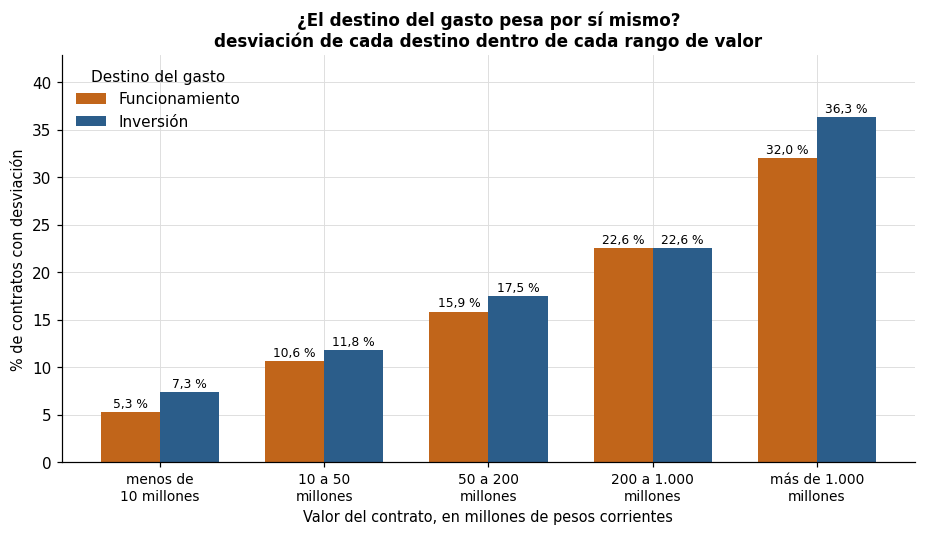

In [20]:
sub = control_destino[control_destino["rango_valor"] != "Todos"]
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(sub))
ancho = 0.36
for k, (col, nombre, color) in enumerate([("funcionamiento_%", "Funcionamiento", NARANJA),
                                          ("inversion_%", "Inversión", AZUL)]):
    xs = x + (k - 0.5) * ancho
    ax.bar(xs, sub[col], width=ancho, color=color, label=nombre)
    for xi, v in zip(xs, sub[col]):
        ax.text(xi, v + 0.5, f"{v:.1f} %".replace(".", ","), ha="center", fontsize=8)
# ETIQ_EJE viene de la seccion 11: los mismos rangos, escritos en palabras.
ax.set_xticks(x, ETIQ_EJE, fontsize=9)
ax.set_xlabel("Valor del contrato, en millones de pesos corrientes", fontsize=9.5)
ax.set_ylabel("% de contratos con desviación", fontsize=9.5)
ax.set_title("¿El destino del gasto pesa por sí mismo?\n"
             "desviación de cada destino dentro de cada rango de valor", fontsize=11)
ax.legend(title="Destino del gasto", loc="upper left")
ax.set_ylim(0, sub[["funcionamiento_%", "inversion_%"]].max().max() * 1.18)
print("figura:", guardar(fig, "control_destino_por_valor"))
plt.show()

### Lectura: el destino del gasto

**Cerca de la mitad de la diferencia bruta es composición.** En bruto, la inversión se desvía más
que el funcionamiento: 15,24 % frente a 12,44 %, 2,80 puntos porcentuales. Pero la inversión firma
contratos más caros: el 18,8 % de sus contratos supera los 200 millones, frente al 14,1 % del
funcionamiento. Si cada contrato se desviara con la tasa de su combinación de modalidad y rango de
valor, la inversión tendría 14,44 % y el funcionamiento 12,97 %: la composición sola produce 1,47
de los 2,80 puntos.

**Lo que queda es pequeño.** Dentro de cada rango de valor la inversión sigue desviándose algo más
en cuatro de los cinco rangos —la diferencia va de 0 a 4,3 puntos y es significativa en esos
cuatro—, pero la V de Cramér no pasa de 0,045 en ninguno, lejos del umbral de 0,10 fijado a
priori. La diferencia mayor está por encima de 1.000 millones (36,3 % frente a 32,0 %), donde los
dos destinos ya quedan dentro de cualquier criterio de focalización por su valor.

**Conclusión.** El destino del gasto no sirve para focalizar: lo que parecía su efecto es en buena
parte el valor de los contratos que lo acompañan, y lo que queda no cambia a quién supervisar. Es
un resultado negativo relevante, porque el enunciado lo sugería como criterio candidato.

In [21]:
# 12.2 El sector y el año de firma: tasa observada frente a la esperada por su
# composicion de modalidad y rango de valor.
def observada_vs_esperada(columna, min_contratos=1000):
    t = (dc.groupby(columna, observed=True)
         .agg(contratos=("desviacion", "size"),
              observada_pct=("desviacion", lambda s: 100 * s.mean()),
              esperada_pct=("tasa_esperada", lambda s: 100 * s.mean())))
    t = t[t["contratos"] >= min_contratos].copy()
    t["razon"] = t["observada_pct"] / t["esperada_pct"]
    return t


por_sector = observada_vs_esperada("sector").sort_values("razon")
por_anio = observada_vs_esperada("anio_firma")
por_anio.index = por_anio.index.astype(int)

control = pd.concat([por_sector.assign(dimension="sector"),
                     por_anio.assign(dimension="año de firma")])
control.rename_axis("categoria").reset_index().to_csv(
    config.TABLAS / "control_composicion.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/control_composicion.csv\n")

print("Sectores con al menos 1.000 contratos, de menor a mayor razón observada / esperada:")
display(por_sector.round(3))
print("Año de firma:")
display(por_anio.round(3))

dc["anio"] = dc["anio_firma"].astype("Int64").astype(str)
r_anio = prueba_chi2(dc, "anio", "desviacion", "control-anio", min_pct=0.0)
p_txt = "< 1e-300" if r_anio["p"] == 0 else f"{r_anio['p']:.1e}"
print(f"chi-cuadrado año de firma x desviación: p {p_txt}, V = {r_anio['valor_efecto']:.3f}")
v_ref = {x: prueba_chi2(dc, x, "desviacion", min_pct=0.0)["valor_efecto"]
         for x in ["banda_valor", "modalidad"]}
print(f"como referencia: V del rango de valor = {v_ref['banda_valor']:.3f}, "
      f"V de la modalidad = {v_ref['modalidad']:.3f}")

escrito: reports/tablas/control_composicion.csv

Sectores con al menos 1.000 contratos, de menor a mayor razón observada / esperada:


,contratos,observada_pct,esperada_pct,razon
sector,,,,
Presidencia de la república,1000,6.800,13.962,0.487
Transporte,4655,10.763,14.343,0.750
Industria,1807,11.013,13.584,0.811
Hacienda y crédito público,2441,11.225,13.262,0.846
Deportes,2610,11.111,12.848,0.865
Agricultura,1254,12.759,14.394,0.886
Ley de justicia,20377,10.330,11.180,0.924
Defensa,34585,14.324,15.482,0.925
Salud y protección social,22037,13.314,13.537,0.984


Año de firma:


,contratos,observada_pct,esperada_pct,razon
anio_firma,,,,
2019,16425,8.049,12.444,0.647
2020,20135,10.752,13.120,0.820
2021,24043,11.039,13.522,0.816
2022,28070,10.584,13.367,0.792
2023,32971,12.174,13.644,0.892
2024,34634,13.827,13.765,1.005
2025,40113,21.659,14.080,1.538


chi-cuadrado año de firma x desviación: p < 1e-300, V = 0.128
como referencia: V del rango de valor = 0.194, V de la modalidad = 0.138


### Lectura: el sector y el año de firma

**El sector.** Frente a lo que anticipa su mezcla de modalidades y valores, Transporte se desvía
bastante menos (10,8 % frente a 14,3 %, razón 0,75) y Trabajo bastante más (19,3 % frente a 13,3 %,
razón 1,45). Los dos extremos coinciden con la zona ciega de H8: Transporte no registra ningún pago
en el 70,1 % de sus contratos y Trabajo es el sector que mejor reporta (32,6 %). Donde no hay pagos
registrados no se puede detectar subejecución, así que una tasa baja puede ser falta de datos y no
cumplimiento. No es una regla general: Salud y protección social, el sector que peor reporta
(74,2 %), se desvía casi lo esperado (13,3 % frente a 13,5 %). El notebook 04 retoma esta lectura
en el frente de calidad del reporte.

**El año de firma.** La tasa sube del 8,0 % en 2019 al 21,7 % en 2025, y la subida no es
composición: 2025 se desvía un 54 % más de lo que anticiparía su mezcla (21,7 % frente a 14,1 %),
mientras que entre 2019 y 2023 todos los años quedan por debajo de lo esperado. El año se asocia
con la desviación casi tanto como la modalidad (V = 0,128 frente a 0,138), aunque menos que el
valor (0,194). Coincide con el salto de la adición registrada que documenta el notebook 01, del
9,3 % en 2024 al 17,3 % en 2025, que puede ser un cambio en el registro de las modificaciones o
en el comportamiento: los datos no permiten separar una cosa de la otra.

Dos consecuencias. Los criterios de focalización deben recalcularse cada año. Y el año no puede
ser un criterio, porque un contrato que se firma hoy no tiene el año de un contrato pasado.

In [22]:
# 12.3 La duracion declarada se conoce a la firma y tiene un gradiente fuerte.
# Antes de usarla como criterio hay que ver si el campo absorbe la propia adicion.
dd = M_TOTAL.dropna(subset=["duracion_dias"]).copy()
dd["duracion"] = pd.cut(dd["duracion_dias"], [-0.01, 30, 90, 180, 365, 1825],
                        labels=["hasta 1 mes", "1 a 3 meses", "3 a 6 meses",
                                "6 a 12 meses", "más de 1 año"])
dd = dd.dropna(subset=["duracion"])
g_dur = dd.groupby("duracion", observed=True)["desviacion"].agg(contratos="size", tasa="mean")
g_dur["tasa_%"] = (100 * g_dur["tasa"]).round(2)
display(g_dur[["contratos", "tasa_%"]])
r_dur = prueba_chi2(dd, "duracion", "desviacion", "control-duracion", min_pct=0.0)
print(f"chi-cuadrado duración x desviación: V = {r_dur['valor_efecto']:.3f} "
      f"(contratos con duración legible: {len(dd):,})\n")

# La evidencia de fuga: si el campo se reescribe tras una adicion, los contratos
# con adicion declararian duraciones mas largas, y nunca menores que la adicion.
con_adic = dd[dd["tiene_adicion"]]
print(f"mediana de la duración declarada: {con_adic['duracion_dias'].median():.0f} días con "
      f"adición, {dd.loc[~dd['tiene_adicion'], 'duracion_dias'].median():.0f} sin ella")
print(f"mediana de la adición: {con_adic['dias_adicionados'].median():.0f} días")
print(f"declaran una duración menor que la adición recibida: "
      f"{100 * (con_adic['duracion_dias'] < con_adic['dias_adicionados']).mean():.1f} %")

,contratos,tasa_%
duracion,,
hasta 1 mes,72422,6.98
1 a 3 meses,46066,15.94
3 a 6 meses,27594,19.61
6 a 12 meses,27508,21.84
más de 1 año,1883,49.76


chi-cuadrado duración x desviación: V = 0.202 (contratos con duración legible: 175,473)

mediana de la duración declarada: 78 días con adición, 59 sin ella
mediana de la adición: 31 días
declaran una duración menor que la adición recibida: 15.6 %


### Lectura: la duración declarada

La duración declarada se conoce a la firma y tiene el gradiente más fuerte de todos: la tasa de
desviación pasa del 7,0 % en los contratos de hasta un mes al 49,8 % en los de más de un año, y
su V de Cramér (0,202) es la mayor de cualquier atributo frente a la desviación, por encima
incluso del valor (0,194). Aun así no se usa como criterio, por dos razones que los datos no permiten descartar:

1. **Puede estar contaminada por la propia adición.** No está claro si el campo se reescribe
   cuando se adiciona plazo, y la evidencia apunta en las dos direcciones. La mediana declarada de
   los contratos con adición es de 78 días frente a 59 sin ella, pero la mediana de la adición es
   de 31 días, y el 15,6 % declara una duración *menor* que la adición recibida. Si el campo se
   actualiza aunque sea parcialmente, la duración «anticipa» una adición que ya ocurrió.
2. **Tiene valores imposibles.** El campo contiene fechas escritas dentro: `30092025 Mes(es)` es
   el 30/09/2025, que leído como duración da 2,5 millones de años. El notebook 01 anuló 99
   registros por encima de los 5 años (paso 5 de la bitácora).

El gradiente admite dos lecturas: un contrato más largo pasa más tiempo expuesto a necesitar una
adición, o el campo absorbe los días adicionados. Los datos no permiten separarlas, y un criterio
que puede estar midiendo el desenlace no sirve para decidir a quién supervisar desde la firma.

---
## 13. Matriz exploratoria: cada característica frente a cada comportamiento

Las hipótesis H1 a H8 cruzan pares elegidos de antemano, y dejan pares sin mirar: la
subejecución solo se cruza con el destino del gasto, y el «tipo de entidad» del enunciado solo
se mide con el orden. Esta sección completa el cuadro: cruza cada característica conocida a la
firma con cada comportamiento que el dataset permite medir.

- **Filas.** Las cinco características del enunciado, con el tipo de entidad en sus tres
  versiones (orden, rama y centralizada o descentralizada), más dos atributos del
  contrato que también se conocen a la firma: el tipo de contrato y la prorrogabilidad (la
  de H5). El valor entra en las cinco bandas de la
  sección 11.
- **Columnas.** La adición de plazo, la subejecución parcial, la desviación que las combina y
  la ausencia de pago registrado, cada una sobre la muestra de su hipótesis: la subejecución
  sobre M_PAGO, como H3, y las demás sobre M_TOTAL.

**Estatus metodológico.** Es una exploración posterior al plan, no un contraste. Reporta solo
la V de Cramér, con el mismo umbral de 0,10, y ningún valor p: a este n todas las celdas serían
significativas, y la sección 10 ya mostró que eso no decide nada. Tampoco se suma a las doce
pruebas primarias, que se fijaron antes de ver los datos: contar como prueba un cruce elegido
después sería buscar resultados a posteriori.

El cierre sin liquidar, la tercera desviación del enunciado, no tiene columna porque la columna
de liquidación no dice si el contrato se liquidó. El final de la sección lo verifica.

In [23]:
# Filas: las caracteristicas del enunciado (el tipo de entidad en sus tres
# versiones) y dos atributos del contrato que tambien se conocen a la firma.
CARACTERISTICAS = {
    "banda_valor": "Valor del contrato",
    "modalidad_de_contratacion": "Modalidad de contratación",
    "sector": "Sector",
    "orden": "Orden de la entidad",
    "rama": "Rama del poder público",
    "entidad_centralizada": "Centralizada o descentralizada",
    "destino_gasto": "Destino del gasto",
    "tipo_de_contrato": "Tipo de contrato",
    "el_contrato_puede_ser_prorrogado": "¿Se puede prorrogar?",
}
N_ENUNCIADO = 7   # las primeras siete filas vienen del enunciado

# Columnas: cada comportamiento con la muestra de su hipotesis. La subejecucion
# solo es observable con pago reportado (M_PAGO, como H3).
COMPORTAMIENTOS = {
    "tiene_adicion": ("Adición de plazo", M_TOTAL),
    "subejecucion_parcial": ("Subejecución parcial", M_PAGO),
    "desviacion": ("Desviación (objetivo)", M_TOTAL),
    "pago_cero": ("Sin pago registrado", M_TOTAL),
}

filas = []
for y, (nombre_y, muestra) in COMPORTAMIENTOS.items():
    m = muestra.copy()
    # Las mismas cinco bandas de la seccion 11, como texto para que agrupar_raras
    # las trate igual que a cualquier otra categorica.
    m["banda_valor"] = pd.cut(m["valor_del_contrato"], CORTES, labels=ETIQ,
                              right=False).astype(object)
    for x, nombre_x in CARACTERISTICAS.items():
        r = prueba_chi2(m, x, y)       # de la prueba solo se usa la V
        t = r["tabla"]
        n_cat = t.sum(axis=1)
        tasa = (100 * t[True] / n_cat)[n_cat >= 500]   # extremos con volumen
        filas.append({
            "caracteristica": nombre_x, "comportamiento": nombre_y,
            "n": r["n"], "categorias": r["categorias"], "V": r["valor_efecto"],
            "supuesto_ok": r["supuesto_ok"],
            "mayor_tasa": f"{tasa.idxmax()} ({tasa.max():.1f} %)",
            "menor_tasa": f"{tasa.idxmin()} ({tasa.min():.1f} %)",
        })

matriz_larga = pd.DataFrame(filas)
matriz_larga.to_csv(config.TABLAS / "matriz_asociacion.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/matriz_asociacion.csv")

matriz = (matriz_larga.pivot(index="caracteristica", columns="comportamiento", values="V")
          .loc[list(CARACTERISTICAS.values()), [c for c, _ in COMPORTAMIENTOS.values()]])
display(matriz.round(3))
print(f"supuesto del chi-cuadrado (esperada >= 5) en todas las celdas: "
      f"{matriz_larga['supuesto_ok'].all()}")

# Control: las celdas que ya tenian prueba primaria deben dar la misma V.
YA_PROBADAS = {
    "H1": ("Modalidad de contratación", "Adición de plazo"),
    "H3": ("Destino del gasto", "Subejecución parcial"),
    "H4-orden": ("Orden de la entidad", "Adición de plazo"),
    "H4-sector": ("Sector", "Adición de plazo"),
    "H5-el_contrato_puede_ser_prorrogado": ("¿Se puede prorrogar?", "Adición de plazo"),
    "H8-orden": ("Orden de la entidad", "Sin pago registrado"),
    "H8-sector": ("Sector", "Sin pago registrado"),
}
v_plan = {r["hipotesis"]: r.get("v_cramer", r["valor_efecto"]) for r in RES}
dif = max(abs(matriz.loc[f, c] - v_plan[h]) for h, (f, c) in YA_PROBADAS.items())
print(f"celdas con prueba primaria: {len(YA_PROBADAS)}; diferencia maxima de V: {dif:.1e}")

escrito: reports/tablas/matriz_asociacion.csv


comportamiento,Adición de plazo,Subejecución parcial,Desviación (objetivo),Sin pago registrado
caracteristica,,,,
Valor del contrato,0.190,0.127,0.194,0.046
Modalidad de contratación,0.144,0.106,0.138,0.146
Sector,0.089,0.099,0.065,0.222
Orden de la entidad,0.015,0.035,0.008,0.037
Rama del poder público,0.012,0.014,0.015,0.051
Centralizada o descentralizada,0.028,0.007,0.023,0.016
Destino del gasto,0.062,0.069,0.040,0.117
Tipo de contrato,0.023,0.227,0.060,0.003
¿Se puede prorrogar?,0.057,0.015,0.044,0.018


supuesto del chi-cuadrado (esperada >= 5) en todas las celdas: True
celdas con prueba primaria: 7; diferencia maxima de V: 0.0e+00


figura: reports/figures/matriz_caracteristica_x_comportamiento.png


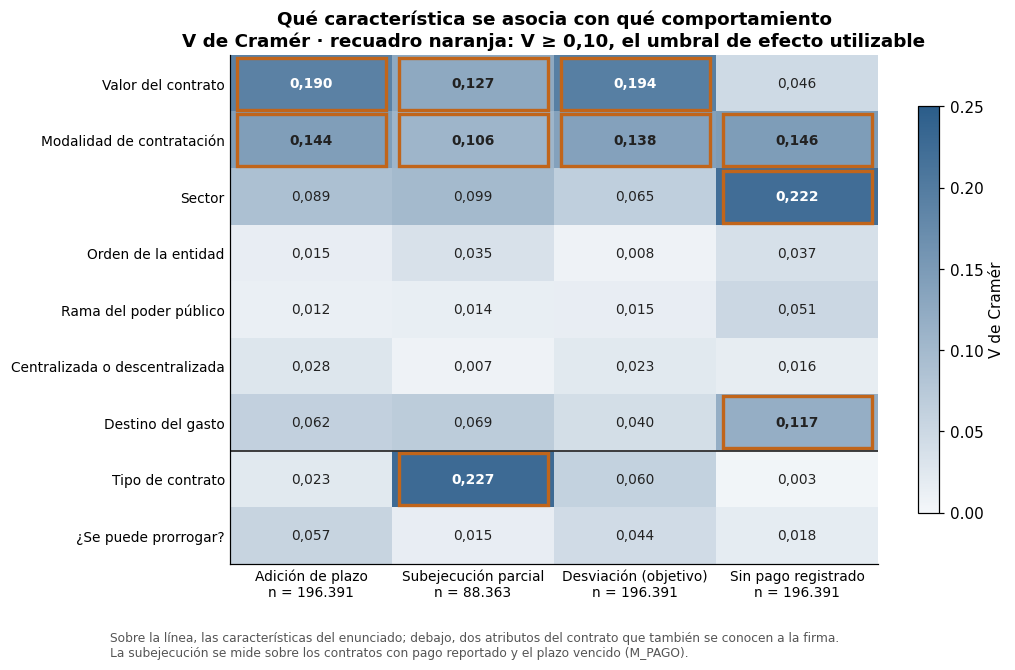

In [24]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

# Escala secuencial de un solo tono: del casi blanco al azul del proyecto.
escala_v = LinearSegmentedColormap.from_list("escala_v", ["#f4f7fa", AZUL])
vals = matriz.values.astype(float)
n_muestra = {nombre: len(muestra) for nombre, muestra in COMPORTAMIENTOS.values()}

fig, ax = plt.subplots(figsize=(9.5, 6))
im = ax.imshow(vals, cmap=escala_v, vmin=0, vmax=0.25, aspect="auto")
ax.set_xticks(range(vals.shape[1]),
              [f"{c}\nn = {n_muestra[c]:,}".replace(",", ".") for c in matriz.columns],
              fontsize=9)
ax.set_yticks(range(vals.shape[0]), matriz.index, fontsize=9)
ax.tick_params(length=0)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        v = vals[i, j]
        util = v >= config.V_MINIMA_UTIL
        ax.text(j, i, f"{v:.3f}".replace(".", ","), ha="center", va="center",
                fontsize=9, fontweight="bold" if util else "normal",
                color="white" if v > 0.15 else "#222")
        if util:
            ax.add_patch(Rectangle((j - 0.46, i - 0.46), 0.92, 0.92, fill=False,
                                   edgecolor=NARANJA, lw=2.2))
# Separa las filas del enunciado de los dos atributos agregados.
ax.axhline(N_ENUNCIADO - 0.5, color="#333", lw=1.2)
ax.grid(False)
ax.set_title("Qué característica se asocia con qué comportamiento\n"
             "V de Cramér · recuadro naranja: V ≥ 0,10, el umbral de efecto utilizable")
fig.colorbar(im, ax=ax, label="V de Cramér", shrink=0.8)
fig.text(0.01, -0.03,
         "Sobre la línea, las características del enunciado; debajo, dos atributos del "
         "contrato que también se conocen a la firma.\nLa subejecución se mide sobre los "
         "contratos con pago reportado y el plazo vencido (M_PAGO).", fontsize=8, color="#555")
print("figura:", guardar(fig, "matriz_caracteristica_x_comportamiento"))
plt.show()

In [25]:
# Las celdas que superan el umbral, con la categoria de mayor y de menor tasa
# (solo categorias con al menos 500 contratos).
utiles = (matriz_larga[matriz_larga["V"] >= config.V_MINIMA_UTIL]
          .sort_values("V", ascending=False)
          .set_index(["caracteristica", "comportamiento"])
          [["V", "mayor_tasa", "menor_tasa"]])
display(utiles.round(3))

# ¿Que parte de la subejecucion aportan los suministros?
es_sum = M_PAGO["tipo_de_contrato"].eq("Suministros")
subej = M_PAGO["subejecucion_parcial"].eq(True)
print(f"suministros: {100 * es_sum.mean():.1f} % de M_PAGO y "
      f"{100 * es_sum[subej].mean():.1f} % de las subejecuciones ({subej.sum():,})")
adic = M_TOTAL.groupby("tipo_de_contrato")["tiene_adicion"].mean().mul(100)
print(f"adicion de plazo: suministros {adic['Suministros']:.1f} %, "
      f"compraventa {adic['Compraventa']:.1f} %")

V                                         mayor_tasa                                    menor_tasa
caracteristica            comportamiento                                                                                                               
Tipo de contrato          Subejecución parcial   0.227                               Suministros (17.0 %)                           Compraventa (3.0 %)
Sector                    Sin pago registrado    0.222                 Salud y protección social (74.2 %)                              Trabajo (32.6 %)
Valor del contrato        Desviación (objetivo)  0.194                                 > 1.000 M (34.2 %)                                < 10 M (5.8 %)
                          Adición de plazo       0.190                                 > 1.000 M (26.9 %)                                < 10 M (3.4 %)
Modalidad de contratación Sin pago registrado    0.146  Contratación régimen especial (con ofertas) (8...  Selección abreviada subasta inversa (48.9 %)
                          Adición de plazo       0.144                        Licitación pública (25.8 %)         Contratación régimen especial (6.2 %)
                          Desviación (objetivo)  0.138                        Licitación pública (34.2 %)        Contratación régimen especial (10.5 %)
Valor del contrato        Subejecución parcial   0.127                                 > 1.000 M (24.6 %)                                < 10 M (6.1 %)
Destino del gasto         Sin pago registrado    0.117                            Funcionamiento (59.4 %)                            Inversión (47.5 %)
Modalidad de contratación Subejecución parcial   0.106                        Licitación pública (26.2 %)                        Mínima cuantía (8.6 %)

suministros: 54.4 % de M_PAGO y 87.2 % de las subejecuciones (9,355)
adicion de plazo: suministros 8.9 %, compraventa 10.3 %


**Lo que la matriz confirma.** Las siete celdas que ya tenían prueba primaria dan exactamente la
misma V, así que la matriz no cambia ningún resultado del plan. Y el criterio de focalización
sale reforzado: **el valor y la modalidad son las únicas características que superan el umbral
en la adición, en la subejecución y en la desviación**. En la adición, el valor pesa incluso más
que la modalidad (V = 0,190 frente a 0,144): los contratos de más de 1.000 millones adicionan
plazo en el 26,9 % de los casos, frente al 3,4 % de los de menos de 10 millones.

**Lo que agrega.**

- **El tipo de entidad queda descartado en sus tres versiones.** Orden, rama y centralizada no
  llegan a 0,06 en ningún comportamiento. H4 solo lo había mostrado para el orden.
- **La mayor asociación de la matriz, tipo de contrato × subejecución (V = 0,227), no estaba en
  el plan.** Es del mismo tamaño que la mayor de las pruebas primarias (H8-sector, 0,222). Los
  suministros subejecutan en el 17,0 % de los casos y las compraventas en el 3,0 %. Son el 54,4 %
  de los contratos con pago reportado y el 87,2 % de las subejecuciones.
- **La ausencia de pago también se asocia con la modalidad (0,146) y con el destino (0,117)**,
  no solo con el sector. La modalidad de régimen especial con ofertas no registra pago en el
  83,6 % de sus contratos, frente al 48,9 % de la subasta inversa. Funcionamiento lo omite en el
  59,4 %, frente al 47,5 % de inversión. El frente de calidad del reporte del notebook 04 puede
  usar esas dos variables además del sector.
- **El destino del gasto pesa en el reporte, no en la ejecución.** Solo supera el umbral en la
  ausencia de pago.

**Una advertencia sobre el tipo de contrato.** Esa asociación puede ser en buena parte
estructural. Un contrato de suministro fija un tope que la entidad consume según la demanda, así
que pagar menos del 90 % del valor puede ser su funcionamiento normal y no un incumplimiento. Hay
un indicio en esa dirección: si los suministros se ejecutaran peor, también adicionarían más
plazo, y no lo hacen (8,9 % frente a 10,3 % de las compraventas, V = 0,023). La diferencia
aparece solo en el pago. El dataset no permite confirmarlo, porque no dice qué contratos son de
monto agotable. Por eso el tipo de contrato no entra en los criterios de focalización del notebook 04: su
asociación con la desviación puede ser la forma del contrato y no el riesgo.

### Por qué el cierre sin liquidar no tiene columna

El diccionario de datos.gov.co define la columna de liquidación como la que «determina si el
contrato ha sido liquidado». Si fuera así, un contrato cuyo plazo sigue corriendo no podría
aparecer como liquidado, porque la liquidación es el cierre formal que viene después de la
ejecución. La celda siguiente lo verifica.

In [26]:
corte = pd.Timestamp(config.FECHA_CORTE)
fin = df["fecha_de_fin_del_contrato"]
liquidado = df["liquidacion"].eq("Si")
vigente = fin.notna() & (fin >= corte)
vencido = fin.notna() & (fin < corte)
en_curso = df["estado_contrato"].isin(["En ejecución", "Modificado"])

print(f"plazo vigente al corte ({corte.date()}): {vigente.sum():,} contratos")
print(f"  marcados como liquidados: {(vigente & liquidado).sum():,} "
      f"({100 * liquidado[vigente].mean():.1f} %)")
print(f"  ... de ellos, en ejecucion o modificados: {(vigente & liquidado & en_curso).sum():,}")
print(f"plazo vencido: {vencido.sum():,} contratos, "
      f"{100 * liquidado[vencido].mean():.1f} % marcados como liquidados")

plazo vigente al corte (2026-09-23): 928 contratos
  marcados como liquidados: 573 (61.7 %)
  ... de ellos, en ejecucion o modificados: 565
plazo vencido: 195,443 contratos, 39.6 % marcados como liquidados


**La columna no mide la liquidación.** Entre los contratos cuyo plazo sigue corriendo, la marca
de liquidado aparece con más frecuencia (61,7 %) que entre los que ya vencieron (39,6 %), y casi
todos esos «liquidados» (565 de 573) siguen en ejecución o modificados. El diccionario del
proyecto (`src/diccionario.py`) ya la describe como «sujeto a liquidación», una lectura que estos
datos no contradicen. Con ella, el tercer comportamiento del enunciado deja de ser medible: la
columna no permite saber qué contratos se cerraron sin liquidar, y el 60,30 % de «No» que el
notebook 01 reporta como la norma administrativa no es una tasa de contratos cerrados sin
liquidar. Lo mismo vale para `n_senales` y `desviacion_severa`, que la cuentan como tercera
señal: el objetivo alternativo del notebook 02 hereda el problema.

---
## Síntesis del desarrollo

Las doce pruebas primarias, todas del inventario del curso. La última columna aplica los dos
criterios fijados a priori: significancia (p < 0,05) **y** tamaño de efecto por
encima de su umbral.

| # | La pregunta | Prueba | p | Efecto | ¿Utilizable para focalizar? |
|---|---|---|---|---|---|
| H1 | ¿Alargar el plazo depende de cómo se contrató? | χ² | < 10⁻³⁰⁰ | V = 0,144 | **Sí** — el mayor efecto sobre la adición |
| H2 | ¿La desviación sube con el precio? | Correlación | 1,8 × 10⁻⁵ | r = 0,954 [0,81; 0,99] | **Sí** — tendencia sin excepciones |
| H2b | ¿Los contratos que se desvían valen más? | Z test | < 10⁻³⁰⁰ | factor **2,81×** [2,74; 2,88] | **Sí** — el criterio más potente |
| H3 | ¿Pagar solo una parte depende del destino del gasto? | χ² | 1,7 × 10⁻⁹⁴ | 4,29 pp [3,88; 4,69] | No — sobre la desviación, su efecto propio es pequeño (§12) |
| H4 | ¿Alargar el plazo depende de si la entidad es nacional o territorial? | χ² | 6,7 × 10⁻¹¹ | V = 0,015 | No — significativo e irrelevante |
| H4 | ¿Alargar el plazo depende del sector? | χ² | 5,3 × 10⁻²⁸⁴ | V = 0,089 | No por sí solo |
| H5 | ¿Se alargan más los contratos prorrogables? | χ² | 1,0 × 10⁻¹³⁸ | V = 0,057 · 4,19 pp [3,82; 4,55] | No — efecto pequeño |
| H5 | ¿Se alargan más los que permiten pago adelantado? | χ² | **0,257** | V = 0,003 · 2,00 pp [−1,47; 5,48] | **No significativo** — sin potencia |
| H6 | Entre los que se alargaron, ¿los días añadidos cambian según el sector? | ANOVA de Welch | 1,3 × 10⁻⁹⁴ | η² = 0,032 | No para focalizar; sí para dimensionar |
| H7 | **Control:** ¿el género del representante tiene que ver con la desviación? | χ² | 8,9 × 10⁻⁴ | V = 0,0094 | **No** — el ejemplo del problema |
| H8 | ¿Dejar de registrar pagos depende de si la entidad es nacional o territorial? | χ² | 7,3 × 10⁻⁵⁸ | V = 0,037 | No |
| H8 | ¿Dejar de registrar pagos depende del sector? | χ² | < 10⁻³⁰⁰ | V = 0,222 | **Sí**, para un frente distinto |

**Cinco de doce** superan su umbral de efecto. De esas cinco, H3 no se traduce en criterio
(su efecto propio sobre la desviación es pequeño, §12) y H8-sector describe el registro y no la ejecución.

**Tres conclusiones.**

1. **Solo dos atributos discriminan de verdad: el valor del contrato y la modalidad de
   contratación.** Se acumulan entre sí y juntos abarcan un rango de más de 12 veces en tasa de
   desviación. Son la base del criterio de focalización.
2. **Entre las pruebas primarias, el hallazgo de mayor tamaño de efecto no es sobre la
   ejecución sino sobre el reporte.**
   La zona ciega de pagos se concentra por sector (V = 0,222), y algunos de los sectores que peor
   reportan, como Transporte, se desvían menos de lo que anticipa su mezcla de valor y
   modalidad (§12). Requiere un frente de acción propio.
3. **Con n ≈ 196.000 el valor p no decide nada.** Once de doce pruebas son significativas; el
   género del representante legal lo es con una diferencia de 0,43 puntos porcentuales. Lo que
   separa lo útil de lo inútil es el tamaño de efecto, fijado como umbral antes de mirar.

Las cuatro verificaciones de robustez no paramétricas —Spearman entre deciles y fila a fila,
Mann-Whitney con delta de Cliff y Kruskal-Wallis— coinciden con su prueba primaria en las tres hipótesis donde
aplican. Quedan registradas en `reports/tablas/pruebas_robustez.csv`.

**El control por composición de la sección 12** confirma que el destino del gasto no sirve
para focalizar: cerca de la mitad de su diferencia bruta es composición y lo que queda no llega
al umbral en ningún rango de valor. Muestra también que el año de firma mueve la tasa casi
tanto como la modalidad (V = 0,128), sin que los datos permitan separar un cambio en el
registro de uno en el comportamiento: los criterios deben recalcularse cada año. Y explica por qué la duración declarada no se usa pese a su gradiente: el
campo puede estar contaminado por la propia adición.

**La matriz exploratoria de la sección 13** no entra en la tabla porque no es una prueba
primaria. Confirma que valor y modalidad son las únicas características con efecto utilizable
sobre la adición, la subejecución y la desviación, y descarta el tipo de entidad en sus tres
versiones. Encuentra fuera del plan una asociación del tamaño de H8-sector, tipo de contrato ×
subejecución (V = 0,227), probablemente estructural. Y verifica que el cierre sin liquidar no se
puede medir con este dataset.